# Track 3 AI Detector: authenticity score for Sentinel-2 tiles

For every 256x256x13 Sentinel-2 tile, one function `authenticity(tile)` returns:

| output | meaning |
|---|---|
| `trust_score` | 0 to 100, high = looks like a real sensor image |
| `channel_flags` | which sanity checks / bands look wrong |
| `heatmap` | 256x256 map of where the tile looks edited |

**Design rules**
1. **Clean-only core.** We never train or tune on attacks. We learn what *clean* tiles look like; anything far from that is suspicious.
2. **Split by scene, not by tile** (train 30 % / calib 45 % / test 25 %). Neighbouring tiles share almost the same pixels, a random split leaks.
3. **Real attacks only, evaluation only.** The teammates' `pair_xxx_original / attacked / masks / manifest` files are used to *measure*, never to choose a threshold, a feature or a rule.
4. **Plain functions, plain arrays.** No custom classes, one idea per cell.

**Pipeline:** `data -> split by scene -> sanity checks -> cross-band models -> features -> clean statistics + thresholds -> authenticity() -> evaluation on real pairs -> diagnostics -> export`

**Fused score (clean-only core):** `max(tile/tile_thr, worst_patch/patch_thr, top-k_feature/fz_thr, heatmap_contrast/hc_thr)`, each term divided by its own clean 99th percentile.

> Kaggle setup: turn **Internet ON** (needed for the TUM download; the archive is streamed, no 33 GB download).
> **Run the cells top to bottom.** Every result cell checks a `build_id` and stops if section 8 was re-run without re-running sections 9 to 14 (stale outputs).

**Revision (2026-11-03).** Clean-only model, paired attacks for evaluation only. The previous notebook outputs were cleared as they were stale. This run prints actual stage-wise diagnostics; no metrics are asserted without access to the clean archive and teammate pair files. Feature preparation and scene split are shared by calibration and deployment. Known fixed-cloud template is an **attack-informed signature** and is reported separately from the clean-only core.

**Baseline supplied by the user (not remeasured here):** pair AUC 0.519; TPR@1% FPR = 0; clean FPR 1.6% (n=126); median runtime ~1.3 s/tile. The *after* outputs must be generated in the dataset environment.


## 1. Config and paths
Everything you may want to change lives in this one cell. To reproduce the "before" numbers set `USE_LOCAL_CONTEXT=False`, `HGB_MAX_ITER=50`, `RUN_TAG="v1"`; the "after" run uses the defaults below with `RUN_TAG="v2"`.

In [2]:
import os, re, io, glob, json, time, hashlib, tarfile, subprocess, warnings, pickle, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

def _ensure(pkg, mod=None):
    try:
        __import__(mod or pkg)
    except ImportError:
        subprocess.run(f"pip -q install {pkg}", shell=True, check=True)
_ensure("rasterio"); _ensure("cryptography")
import rasterio

# ---------- paths ----------
#TUM_URL   = "https://dataserv.ub.tum.de/s/m1554803/download?path=%2F&files=ROIs1158_spring_s2.tar.gz"
DATA_DIR  = "/kaggle/temp/tum_data"
#ARCHIVE   = f"{DATA_DIR}/ROIs1158_spring_s2.tar.gz"      # used if it already exists, otherwise streamed
#TILE_DIR  = f"{DATA_DIR}/tiles"                          # the subset we keep
SEASON_ARCHIVES = {
    "spring": "ROIs1158_spring_s2.tar.gz",
    "summer": "ROIs1868_summer_s2.tar.gz",
    "fall":   "ROIs1970_fall_s2.tar.gz",
    "winter": "ROIs2017_winter_s2.tar.gz",
}
ARCHIVE= SEASON_ARCHIVES
TUM_BASE = "https://dataserv.ub.tum.de/s/m1554803/download?path=%2F&files="

TILES_PER_SEASON = 600   # 4 x 600 = 2400 clean tiles
MAX_PER_SCENE    = 20    # diversity: many scenes, few tiles each
TILE_STRIDE      = 8     # keep every 8th patch of a scene (spread over the scene)
ATTACK_SOURCE_N  = 800   # first N tifs of each archive = originals used by the attack generator -> never used for training

TILE_DIR = f"{DATA_DIR}/tiles_4seasons"       # new folder: do not mix with the old spring-only cache
os.makedirs(TILE_DIR, exist_ok=True)
OUT_DIR   = "/kaggle/working/outputs"

# ---------- clean data subset ----------
N_TILES        = 1800    # total tiles to keep
MAX_PER_SCENE  = 45     # 41 scenes in archive * 20 = ~800 tiles
TILE_STRIDE    = 1      # stride 2 so scenes with <80 patches still yield 20 tiles
MIN_SCENES     = 100

# ---------- split (by scene) ----------
SPLIT_FRACS = {"train": 0.35, "calib": 0.45, "test": 0.20}
# train = fit the cross-band regressors | calib = clean statistics + thresholds | test = honest false-positive rate

# ---------- sensor / model constants ----------
BAND_NAMES   = ["B1","B2","B3","B4","B5","B6","B7","B8","B8A","B9","B10","B11","B12"]
TARGET_BANDS = ["B2","B3","B4","B5","B8","B11","B12"]   # 7 bands predicted from the others (cross-band regressors)
PATCH, PATCH_STRIDE = 32, 16                            # 15 x 15 grid of 32x32 patches at stride 16
FPR_TARGET   = 0.01                                     # 1 % false positives on clean data
SEED = 42
B = {n: i for i, n in enumerate(BAND_NAMES)}            # band name -> index

# ---------- cross-band regressors (step 4) ----------
USE_LOCAL_CONTEXT = True    # add the 3x3 local mean of every OTHER band as extra inputs
HGB_MAX_ITER      = 150     # was 50
# ---------- fused score ----------
FZ_K        = 3
Z_CLIP      = 20.0
PREDICT_STRIDE = 2   # deterministic fast inference; training still on clean sampled pixels                                         # top-k extreme features (step 2)
ALL_TERMS   = ["tile", "patch", "fz", "hc"]             # tile Mahalanobis, worst patch, top-k feature, heatmap contrast
FUSED_TERMS = ["tile", "patch", "fz", "hc"]             # terms used by authenticity() (fixed a priori)
RUN_TAG     = "v3_clean_only"                                      # tag of the saved summary, to compare runs
print("config ok | rasterio", rasterio.__version__, "| local context:", USE_LOCAL_CONTEXT, "| max_iter:", HGB_MAX_ITER)

config ok | rasterio 1.5.2 | local context: True | max_iter: 150


In [6]:
# Kaggle dataset slug spelling varies; prefer the directory that actually contains pair originals.
PAIR_DIR_CANDIDATES = [
    "/kaggle/input/datasets/pairs"
    ]
PAIRS_DIR = next(
    (p for p in PAIR_DIR_CANDIDATES
     if os.path.isdir(p) and glob.glob(os.path.join(p, "**", "*_original.tif"), recursive=True)),
    PAIR_DIR_CANDIDATES[0],
)  # teammates' pair_xxx_* files
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)


**Data prerequisites.** Mount the real teammate dataset (original/attacked/mask/manifest) and at least one clean SEN12MS-CR archive. A single `ROIs1158_spring_s2` archive may not reach 100 distinct scenes: the notebook prints an unmet-target warning rather than fabricating scenes. Cache lives in `TILE_DIR`; leave it intact between runs.

## 2. Get the clean data (SEN12MS-CR, Sentinel-2 only)

Source: TUM server, `ROIs1158_spring_s2.tar.gz`. Tiles are named `ROIs1158_spring/s2_<scene>/ROIs1158_spring_s2_<scene>_p<patch>.tif`, so **ROI + scene id** is our "region".

`get_tiles()` reads the local archive if it exists, otherwise **streams** it over HTTP and stops after `N_TILES` (no 33 GB download). It keeps at most `MAX_PER_SCENE` tiles per scene (every `TILE_STRIDE`-th one). The kept tiles are tagged with the config that produced them, so changing `N_TILES / MAX_PER_SCENE / TILE_STRIDE` re-extracts automatically.

In [3]:
# ============================================================
# CLEAN TILES FROM 4 SEASONS (spring, summer, fall, winter)
# ============================================================
from tqdm.auto import tqdm



TILE_RE = re.compile(r"(ROIs\d+_[a-z]+)_s2_(\d+)_p(\d+)\.tif$")

def parse_tile_name(name):
    '''".../ROIs1868_summer_s2_17_p203.tif" -> dict(roi, scene, patch); None if not a tile.'''
    m = TILE_RE.search(name)
    if m is None:
        return None
    return dict(roi=m.group(1), scene=int(m.group(2)), patch=int(m.group(3)))

def walk_archive(tar, desc):
    '''One pass over the tar: skip the attack-source scenes, keep a capped, strided subset of the others.'''
    seen, taken, blocked = {}, {}, set()
    n_tif = kept = 0
    with tqdm(total=TILES_PER_SEASON, desc=desc, unit="tile") as pbar:
        for member in tar:
            if not member.isfile() or not member.name.lower().endswith((".tif", ".tiff")):
                continue
            n_tif += 1                                   # same counting as the attack generator
            if n_tif % 200 == 0:                         # refresh the counters without slowing the loop
                pbar.set_postfix(scanned=n_tif, scenes=len(taken), blocked=len(blocked))
            info = parse_tile_name(member.name)
            if info is None:
                continue
            key = (info["roi"], info["scene"])
            if n_tif <= ATTACK_SOURCE_N:                 # scenes of the attack originals: blocked entirely
                blocked.add(key)
                continue
            if key in blocked:
                continue
            seen[key] = seen.get(key, 0) + 1
            if taken.get(key, 0) >= MAX_PER_SCENE or seen[key] % TILE_STRIDE != 0:
                continue
            out_path = os.path.join(TILE_DIR, os.path.basename(member.name))
            if not os.path.exists(out_path):
                with open(out_path, "wb") as f:
                    f.write(tar.extractfile(member).read())
            taken[key] = taken.get(key, 0) + 1
            kept += 1
            pbar.update(1)
            if kept >= TILES_PER_SEASON:
                break
        pbar.set_postfix(scanned=n_tif, scenes=len(taken), blocked=len(blocked))
    return taken, blocked

def get_season(season, archive_name, retries=3):
    marker = os.path.join(TILE_DIR, f"_done_{season}.json")
    if os.path.exists(marker):
        info = json.load(open(marker))
        print(f"[{season}] already done: {info['tiles']} tiles, {info['scenes']} scenes (skipped)")
        return
    local = f"{DATA_DIR}/{archive_name}"
    t0 = time.time()
    for attempt in range(1, retries + 1):
        try:
            desc = f"{season} (try {attempt}/{retries})"
            if os.path.exists(local):
                with tarfile.open(local, "r|gz") as tar:
                    taken, blocked = walk_archive(tar, desc)
            else:
                import requests
                r = requests.get(TUM_BASE + archive_name, stream=True, timeout=(30, 300))
                r.raise_for_status()
                with tarfile.open(fileobj=r.raw, mode="r|gz") as tar:
                    taken, blocked = walk_archive(tar, desc)
                r.close()
            break
        except Exception as e:                       # connection dropped: restart (existing files are not rewritten)
            print(f"[{season}] attempt {attempt}/{retries} failed: {e}")
            time.sleep(5)
            if attempt == retries:
                raise
    n = sum(taken.values())
    json.dump(dict(tiles=n, scenes=len(taken), blocked_scenes=sorted(f"{a}_s2_{b}" for a, b in blocked)),
              open(marker, "w"))
    print(f"[{season}] {n} tiles from {len(taken)} scenes | blocked attack-source scenes: "
          f"{len(blocked)} | {time.time()-t0:.0f}s")

from concurrent.futures import ThreadPoolExecutor

def get_tiles():
    with ThreadPoolExecutor(max_workers=4) as ex:
        list(ex.map(lambda kv: get_season(*kv), SEASON_ARCHIVES.items()))
    print("total tiles on disk:", len(glob.glob(f"{TILE_DIR}/*.tif")))

get_tiles()



winter (try 1/3):   0%|          | 0/600 [00:00<?, ?tile/s]

fall (try 1/3):   0%|          | 0/600 [00:00<?, ?tile/s]

summer (try 1/3):   0%|          | 0/600 [00:00<?, ?tile/s]

spring (try 1/3):   0%|          | 0/600 [00:00<?, ?tile/s]

[winter] 600 tiles from 14 scenes | blocked attack-source scenes: 2 | 2447s
[fall] 600 tiles from 14 scenes | blocked attack-source scenes: 2 | 2515s
[summer] 600 tiles from 14 scenes | blocked attack-source scenes: 1 | 2537s
[spring] 600 tiles from 14 scenes | blocked attack-source scenes: 2 | 2726s
total tiles on disk: 2400


## 3. Region split and hash exclusion

Clean tiles are split by source scene, never randomly by tile. Teammate originals are mapped to source scenes using explicit filenames in manifests first, then exact pixel hashes or exact GeoTIFF grid metadata. A mapping is accepted only when unambiguous.

If a pair cannot be mapped, the notebook now reports it and continues by default instead of crashing. **That warning is important:** the source scene for that pair could not be excluded, so overlap/leakage is not ruled out for that pair. Set `UNMAPPED_SOURCE_POLICY = "error"` in the split cell to enforce strict fail-fast behavior. Do not report a fully leakage-controlled evaluation while unresolved pairs remain.


In [7]:
def read_tile(path):
    """Read a GeoTIFF as a numpy array (bands, H, W); preserve stored dtype."""
    with rasterio.open(path) as src:
        return src.read()

def pixel_hash(arr):
    return hashlib.sha256(np.ascontiguousarray(arr).tobytes()).hexdigest()

def list_tiles():
    rows = []
    for p in sorted(glob.glob(os.path.join(TILE_DIR, "*.tif"))):
        info = parse_tile_name(os.path.basename(p))
        if info:
            rows.append(dict(path=p, scene_key=f"{info['roi']}_s2_{info['scene']}", **info))
    return pd.DataFrame(rows, columns=["path", "scene_key", "roi", "scene", "patch"])

def split_by_scene(df, fracs, seed=SEED):
    '''Scene-level split, done separately inside each season (ROI), so every split sees all 4 seasons.'''
    split_of = {}
    for roi, g in df.groupby("roi"):
        scenes = np.array(sorted(g["scene_key"].unique()))
        if len(scenes) < 3:
            raise ValueError(f"{roi}: only {len(scenes)} scenes, need >= 3")
        np.random.default_rng(seed).shuffle(scenes)
        n = len(scenes)
        n_tr = min(max(1, int(round(n * fracs["train"]))), n - 2)
        n_ca = min(max(1, int(round(n * fracs["calib"]))), n - n_tr - 1)
        for i, s in enumerate(scenes):
            split_of[s] = "train" if i < n_tr else "calib" if i < n_tr + n_ca else "test"
    out = df.copy()
    out["split"] = out["scene_key"].map(split_of)
    print(pd.crosstab(out["roi"], out["split"], values=out["scene_key"], aggfunc="nunique"))
    return out
    

FAMILY_KEYS = ["attack_family", "attack_type", "family", "attack", "type", "kind", "name"]

def _manifest_candidates(original_path):
    """Find likely pair-local manifests, including common alternate names."""
    base = original_path[:-len("_original.tif")] if original_path.endswith("_original.tif") else os.path.splitext(original_path)[0]
    folder = os.path.dirname(original_path)
    pair_id = os.path.basename(base)
    candidates = [
        base + "_manifest.json",
        base + ".json",
        os.path.join(folder, pair_id + "_manifest.json"),
        os.path.join(folder, "manifest.json"),
        os.path.join(folder, pair_id, "manifest.json"),
    ]
    # Also search pair-local JSON manifests with alternate naming.
    candidates.extend(glob.glob(os.path.join(folder, "*manifest*.json")))
    return list(dict.fromkeys(p for p in candidates if os.path.isfile(p)))

def _load_manifest(original_path):
    for mp in _manifest_candidates(original_path):
        try:
            with open(mp, "r", encoding="utf-8") as f:
                return json.load(f), mp
        except (OSError, json.JSONDecodeError):
            continue
    return None, None

def get_family(manifest_path):
    if not os.path.isfile(manifest_path):
        return "unknown"
    try:
        with open(manifest_path, "r", encoding="utf-8") as f:
            data = json.load(f)
    except (OSError, json.JSONDecodeError):
        return "unknown"
    def search(obj):
        if isinstance(obj, dict):
            for key in FAMILY_KEYS:
                if key in obj and isinstance(obj[key], str) and obj[key].strip():
                    return obj[key].strip()
            for value in obj.values():
                found = search(value)
                if found:
                    return found
        elif isinstance(obj, list):
            for value in obj:
                found = search(value)
                if found:
                    return found
        return None
    return search(data) or "unknown"

def find_pairs(pairs_dir):
    """Discover pair originals recursively and tolerate missing attacked/mask/manifest files."""
    roots = [pairs_dir]
    if not any(os.path.isdir(root) and glob.glob(os.path.join(root, "**", "*_original.tif"), recursive=True)
               for root in roots):
        roots = [p for p in PAIR_DIR_CANDIDATES if os.path.isdir(p)]
    originals = []
    for root in roots:
        if os.path.isdir(root):
            originals.extend(glob.glob(os.path.join(root, "**", "*_original.tif"), recursive=True))
    originals = sorted(set(originals))
    rows = []
    for orig in originals:
        base = orig[:-len("_original.tif")]
        att = base + "_attacked.tif"
        msk = base + "_masks.npz"
        manifest, manifest_path = _load_manifest(orig)
        rows.append(dict(
            pair_id=re.sub(r"[^A-Za-z0-9_.-]+", "__", os.path.relpath(base, root)),
            original=orig,
            attacked=att if os.path.isfile(att) else None,
            gt=msk if os.path.isfile(msk) else None,
            manifest=manifest_path,
            family=get_family(manifest_path) if manifest_path else "unknown",
        ))
    result = pd.DataFrame(rows, columns=["pair_id", "original", "attacked", "gt", "manifest", "family"])
    if not result["pair_id"].is_unique:
        raise ValueError("Pair keys must be unique across attack-family folders")
    return result

# Locate the real teammate dataset even if the Kaggle slug uses a hyphen/no-hyphen variant.
pairs = find_pairs(PAIRS_DIR)
assert len(pairs), (
    "No teammate *_original.tif files found. Check the attached Kaggle dataset and PAIRS_DIR. "
    f"Checked: {PAIR_DIR_CANDIDATES}"
)

whole = list_tiles()
assert len(whole), f"No extracted clean TIFF tiles in {TILE_DIR}"

# Index clean tiles using three evidence sources: explicit source filename in manifest,
# exact pixel content, and exact GeoTIFF grid metadata. No approximate nearest-neighbour guesses.
hash_to_scenes = {}
meta_to_scenes = {}
for _, tile in whole.iterrows():
    path = tile["path"]
    scene_key = tile["scene_key"]
    try:
        arr = read_tile(path)
        hash_to_scenes.setdefault(pixel_hash(arr), set()).add(scene_key)
        with rasterio.open(path) as src:
            meta_key = (
                tuple(src.transform), str(src.crs), tuple(src.shape), src.count
            )
        meta_to_scenes.setdefault(meta_key, set()).add(scene_key)
    except Exception as exc:
        print(f"WARNING: unable to index clean tile {path}: {exc}")

def scene_from_original(path):
    """Return one source scene only when evidence identifies it unambiguously."""
    # 1) Original itself may retain a canonical SEN12MS filename.
    info = parse_tile_name(os.path.basename(path))
    if info:
        return f"{info['roi']}_s2_{info['scene']}", "filename"

    # 2) Look for canonical source tile filenames anywhere in the pair manifest.
    manifest, manifest_path = _load_manifest(path)
    if manifest is not None:
        serialized = json.dumps(manifest, ensure_ascii=False)
        tokens = re.findall(
            r"ROIs\d+_[a-z]+_s2_\d+_p\d+\.tif", serialized, flags=re.IGNORECASE
        )
        token_scenes = set()
        for token in tokens:
            token_info = parse_tile_name(os.path.basename(token))
            if token_info:
                token_scenes.add(f"{token_info['roi']}_s2_{token_info['scene']}")
        if len(token_scenes) == 1:
            return next(iter(token_scenes)), f"manifest:{os.path.basename(manifest_path)}"
        # Multiple scene keys in a manifest are not safe to resolve automatically.

    # 3) Exact pixel-array match (ignores TIFF compression and GeoTIFF metadata).
    try:
        arr = read_tile(path)
        matches = hash_to_scenes.get(pixel_hash(arr), set())
        if len(matches) == 1:
            return next(iter(matches)), "exact-pixel-match"
    except Exception:
        pass

    # 4) Exact GeoTIFF metadata match; only accept if it points to one scene.
    try:
        with rasterio.open(path) as src:
            meta_key = (tuple(src.transform), str(src.crs), tuple(src.shape), src.count)
        matches = meta_to_scenes.get(meta_key, set())
        if len(matches) == 1:
            return next(iter(matches)), "exact-geospatial-metadata"
    except Exception:
        pass

    return None, "unresolved"

# Default is "warn": continue the clean-only experiment but explicitly disclose that
# exclusion could not be verified for unmapped pairs. Set to "error" for strict mode.
UNMAPPED_SOURCE_POLICY = "warn"  # "warn" or "error"

mapping_rows = []
blocked_scenes = set()
for _, pair in pairs.iterrows():
    scene_key, method = scene_from_original(pair["original"])
    mapping_rows.append(dict(pair_id=pair["pair_id"], original=pair["original"],
                             source_scene=scene_key, mapping_method=method))
    if scene_key is not None:
        blocked_scenes.add(scene_key)

source_mapping = pd.DataFrame(mapping_rows)
unmapped = source_mapping[source_mapping["source_scene"].isna()]
print("teammate pairs discovered:", len(pairs))
print("source scenes resolved:", len(source_mapping) - len(unmapped), "/", len(source_mapping))
print("mapping methods:", source_mapping["mapping_method"].value_counts().to_dict())
if len(unmapped):
    message = (
        f"{len(unmapped)} teammate original(s) could not be mapped to a clean source scene. "
        "Those scenes cannot be excluded with the evidence available; scene-overlap/leakage "
        "is therefore NOT ruled out for those pairs. Inspect source_mapping and the pair manifests."
    )
    if UNMAPPED_SOURCE_POLICY == "error":
        raise ValueError(message)
    print("WARNING:", message)
    display(unmapped[["pair_id", "original", "mapping_method"]])

df = whole.loc[~whole["scene_key"].isin(blocked_scenes)].copy()
print("excluded teammate source scenes:", sorted(blocked_scenes))
print("excluded clean tiles:", len(whole) - len(df), "of", len(whole))
assert not (set(df["scene_key"]) & blocked_scenes), "Scene leakage with mapped teammate originals"

df = split_by_scene(df, SPLIT_FRACS).reset_index(drop=True)
assert df.groupby("scene_key")["split"].nunique().max() == 1
split_sets = {name: set(df.loc[df["split"] == name, "scene_key"]) for name in ["train", "calib", "test"]}
assert not (split_sets["train"] & split_sets["calib"])
assert not (split_sets["train"] & split_sets["test"])
assert not (split_sets["calib"] & split_sets["test"])

if df["scene_key"].nunique() < MIN_SCENES:
    print(f"UNMET data target: {df['scene_key'].nunique()} scenes (<{MIN_SCENES}); do not claim robust validation")
if len(df) < 1500:
    print(f"UNMET tile target: only {len(df)} clean tiles")
print("clean scene keys:", df["scene_key"].nunique())
display(df.groupby("split").agg(tiles=("path", "size"), scenes=("scene_key", "nunique")))
paths = {name: df.loc[df["split"] == name, "path"].tolist() for name in ["train", "calib", "test"]}
assert all(os.path.exists(path) for split_paths in paths.values() for path in split_paths), (
    "Tile list is stale: rerun the data cell and this cell."
)

teammate pairs discovered: 710
source scenes resolved: 0 / 710
mapping methods: {'unresolved': 710}


,pair_id,original,mapping_method
0,BLACK_PIXEL_250_PER_ATTACK__fall__copy_move_cl...,/kaggle/input/datasets/onsgui/pairs/BLACK_PIXE...,unresolved
1,BLACK_PIXEL_250_PER_ATTACK__fall__copy_move_cl...,/kaggle/input/datasets/onsgui/pairs/BLACK_PIXE...,unresolved
2,BLACK_PIXEL_250_PER_ATTACK__fall__copy_move_cl...,/kaggle/input/datasets/onsgui/pairs/BLACK_PIXE...,unresolved
3,BLACK_PIXEL_250_PER_ATTACK__fall__copy_move_cl...,/kaggle/input/datasets/onsgui/pairs/BLACK_PIXE...,unresolved
4,BLACK_PIXEL_250_PER_ATTACK__fall__copy_move_cl...,/kaggle/input/datasets/onsgui/pairs/BLACK_PIXE...,unresolved
...,...,...,...
705,BLACK_PIXEL_250_PER_ATTACK__winter__scanline_s...,/kaggle/input/datasets/onsgui/pairs/BLACK_PIXE...,unresolved
706,BLACK_PIXEL_250_PER_ATTACK__winter__scanline_s...,/kaggle/input/datasets/onsgui/pairs/BLACK_PIXE...,unresolved
707,BLACK_PIXEL_250_PER_ATTACK__winter__scanline_s...,/kaggle/input/datasets/onsgui/pairs/BLACK_PIXE...,unresolved
708,BLACK_PIXEL_250_PER_ATTACK__winter__scanline_s...,/kaggle/input/datasets/onsgui/pairs/BLACK_PIXE...,unresolved


excluded teammate source scenes: []
excluded clean tiles: 0 of 2400
split            calib  test  train
roi                                
ROIs1158_spring      6     3      5
ROIs1868_summer      6     3      5
ROIs1970_fall        6     3      5
ROIs2017_winter      6     3      5
UNMET data target: 56 scenes (<100); do not claim robust validation
clean scene keys: 56


,tiles,scenes
split,,
calib,960,24
test,540,12
train,900,20


In [8]:
# merge train + calib into ONE pool (cross-fitted by scene in the next step); test stays untouched
df.loc[df["split"] == "train", "split"] = "calib"
paths["calib"] = df.loc[df["split"] == "calib", "path"].tolist()
print("pool scenes:", df.loc[df["split"] == "calib", "scene_key"].nunique(),
      "| pool tiles:", len(paths["calib"]),
      "| test scenes:", df.loc[df["split"] == "test", "scene_key"].nunique())

pool scenes: 44 | pool tiles: 1860 | test scenes: 12


## 4. Preprocessing and sanity checks

Two views of the same tile:
* **raw DN** (`uint16`, reflectance x 10000): used for the cheap integrity checks.
* **reflectance** (`/10000`, clipped to 0..1.5): used for all features.

In SEN12MS-CR the 20 m and 60 m bands are already resampled onto the 10 m grid, so every band is 256x256.

Cheap checks, each one becomes a flag in `channel_flags`: band count, shape, dtype, NaN, out-of-range values.
The dtype check compares to the dtype **most clean tiles have**, so it cannot fire on every clean tile by mistake.

> The old `fixed_cloud_pattern` rule (bright B2/B3/B4 > 0.3 equals 32 % +/- 0.5 %) never fired on the real cloud pairs, because the original tile's own bright pixels and the cloud's real brightness make the bright fraction differ from exactly 32 %. It was removed from this cell. A replacement **signature rule** (a fixed spatial template) lives in section 10b and is reported **separately** from the clean-only core.

In [9]:
def to_reflectance(arr):
    '''uint16 DN -> float reflectance in [0, 1.5].'''
    x = np.nan_to_num(arr.astype(np.float32)) / 10000.0
    return np.clip(x, 0, 1.5)

def sanity_checks(arr, expected_dtype):
    '''Returns a dict of boolean flags. True = something is wrong.
    `fixed_cloud_pattern` is only filled by the signature rule of section 10b (False here).'''
    flags = {
        "band_count_bad": arr.shape[0] != 13,
        "shape_bad": tuple(arr.shape[1:]) != (256, 256),
        "dtype_differs_from_clean": str(arr.dtype) != str(expected_dtype),
        "has_nan": bool(np.isnan(arr).any()) if arr.dtype.kind == "f" else False,
        "out_of_range": False,
        "fixed_cloud_pattern": False,
    }
    if flags["band_count_bad"] or flags["shape_bad"]:
        return flags                      # the rest needs a valid layout
    refl = np.nan_to_num(arr.astype(np.float32)) / 10000.0
    flags["out_of_range"] = bool((refl < 0).any() or (refl > 1.5).mean() > 0.001)
    return flags

# learn the expected dtype from the training tiles, then look at flag rates on clean data
dtypes = pd.Series([str(read_tile(p).dtype) for p in paths["train"][:50]])
EXPECTED_DTYPE = dtypes.mode()[0]
print("expected dtype:", EXPECTED_DTYPE, "| seen:", dict(dtypes.value_counts()))

flag_table = pd.DataFrame([sanity_checks(read_tile(p), EXPECTED_DTYPE) for p in paths["calib"][:100]])
print("\nflag rate on clean calibration tiles (should be ~0):")
print(flag_table.mean().round(3))

expected dtype: uint16 | seen: {'uint16': np.int64(50)}

flag rate on clean calibration tiles (should be ~0):
band_count_bad              0.0
shape_bad                   0.0
dtype_differs_from_clean    0.0
has_nan                     0.0
out_of_range                0.0
fixed_cloud_pattern         0.0
dtype: float64


## 5. Feature family A: cross-band consistency

**Idea.** On a real sensor the 13 bands are tied by physics (vegetation reflects NIR, water absorbs SWIR...). If someone edits a region, they rarely keep these relations exact.

**Method.** For each of the **7 target bands** (B2, B3, B4, B5, B8, B11, B12) we train a `HistGradientBoostingRegressor` that predicts it, pixel by pixel, on clean `train` tiles. Inputs:
* the **12 other bands**, and (if `USE_LOCAL_CONTEXT`) the **3x3 local mean of each of those 12 other bands** (24 inputs).
* The target band's own 3x3 mean is deliberately **excluded**: it contains the target pixel itself, so the model would just copy it and stop seeing inconsistencies.

At test time: `error map = |predicted - actual|`, divided by the **clean error scale** (mean error on clean `calib` tiles, which the regressors have never seen).
A large ratio means "this pixel does not look like the other bands say it should".

In [10]:
from sklearn.ensemble import HistGradientBoostingRegressor
from scipy.ndimage import uniform_filter, sobel, zoom
from tqdm.auto import tqdm

def local_means(refl):
    '''3x3 local mean of every band -> (13, 256, 256).'''
    return np.stack([uniform_filter(refl[i], size=3) for i in range(13)])

def pixel_inputs(refl):
    '''(65536, 13) bands, or (65536, 26) bands + their 3x3 local means.'''
    flat = refl.reshape(13, -1)
    if USE_LOCAL_CONTEXT:
        flat = np.vstack([flat, local_means(refl).reshape(13, -1)])
    return flat.T

def input_cols(t):
    '''Columns used to predict band t: every column except the band itself (and its own local mean).'''
    n = 26 if USE_LOCAL_CONTEXT else 13
    drop = {t, t + 13} if USE_LOCAL_CONTEXT else {t}
    return [i for i in range(n) if i not in drop]

def sample_pixels(refl, n, r):
    '''n random pixels of a tile -> array (n, 13 or 26).'''
    X = pixel_inputs(refl)
    return X[r.choice(X.shape[0], n, replace=False)]

def fit_cross_band_models(train_paths, n_per_tile=1500):
    r = np.random.default_rng(SEED)                      # fresh RNG: same result on every run
    X = np.vstack([sample_pixels(to_reflectance(read_tile(p)), n_per_tile, r) for p in train_paths])
    print("regression training pixels:", X.shape)
    models = {}
    for b in TARGET_BANDS:
        t = B[b]
        m = HistGradientBoostingRegressor(max_iter=HGB_MAX_ITER, max_leaf_nodes=15, learning_rate=0.1, random_state=SEED)
        m.fit(X[:, input_cols(t)], X[:, t])
        models[b] = m
    return models

def error_maps(refl, regressors, stride=PREDICT_STRIDE):
    """Evaluate HGB on a stride grid; same procedure in calibration and deployment."""
    from scipy.ndimage import zoom
    s = int(stride)
    assert s in (1,2,4) and refl.shape == (13,256,256)
    full = pixel_inputs(refl).reshape(256,256,-1)
    grid = full[::s,::s,:].reshape(-1,full.shape[-1])
    maps={}
    for b,m in regressors.items():
        t = B[b]
        pred=m.predict(grid[:,input_cols(t)]).reshape(256//s,256//s)
        if s != 1: pred=zoom(pred,(s,s),order=1)[:256,:256]
        maps[b]=np.abs(pred-refl[t]).astype(np.float32)
    return maps

def clean_error_scale(maps_by_tile, n_pix=4000):
    '''Mean clean error per band (the "clean error scale") and the clean 99th percentile of err/scale.'''
    r = np.random.default_rng(SEED + 1)
    pool = {b: [] for b in TARGET_BANDS}
    for maps in maps_by_tile.values():
        for b in TARGET_BANDS:
            pool[b].append(r.choice(maps[b].ravel(), n_pix, replace=False))
    err_scale = {b: float(np.concatenate(pool[b]).mean()) for b in TARGET_BANDS}
    p99_ref = {b: float(np.percentile(np.concatenate(pool[b]) / err_scale[b], 99)) for b in TARGET_BANDS}
    return err_scale, p99_ref

t0 = time.time()
regressors = fit_cross_band_models(paths["train"])
#print(f"regressors fitted in {time.time()-t0:.0f}s")

# error maps of the clean calibration tiles are computed ONCE and cached (float32);
# section 8 reuses them (and recomputes them if the cache was cleared)
#calib_maps = {p: error_maps(to_reflectance(read_tile(p)), regressors) for p in tqdm(paths["calib"])}
from sklearn.model_selection import GroupKFold

pool_paths  = paths["calib"]
pool_groups = df.loc[df["split"] == "calib", "scene_key"].values      # same order as pool_paths
N_FOLDS = 5

calib_maps = {}
for k, (tr, te) in enumerate(GroupKFold(N_FOLDS).split(pool_paths, groups=pool_groups)):
    print(f"fold {k+1}/{N_FOLDS}: fit on {len(set(pool_groups[tr]))} scenes, score {len(set(pool_groups[te]))} unseen scenes")
    reg_k = fit_cross_band_models([pool_paths[i] for i in tr], n_per_tile=800)
    for i in tqdm(te, desc=f"fold {k+1} error maps"):
        maps = error_maps(to_reflectance(read_tile(pool_paths[i])), reg_k)
        calib_maps[pool_paths[i]] = {b: m.astype(np.float16) for b, m in maps.items()}   # float16 saves RAM

# final regressors: all pool scenes (this is what authenticity() deploys)
regressors = fit_cross_band_models(pool_paths, n_per_tile=800)

err_scale, p99_ref = clean_error_scale(calib_maps)
# Clean-only pixel residual baselines, calibrated from a deterministic sample of clean tiles.
pix_rng=np.random.default_rng(SEED+88)
pixel_log_center={}
pixel_log_scale={}
for band in TARGET_BANDS:
    sample=np.concatenate([pix_rng.choice(np.log1p(maps[band].ravel()/max(err_scale[band],1e-8)),
                     size=min(2000,maps[band].size), replace=False) for maps in calib_maps.values()])
    mid=np.median(sample)
    scale=max(1.4826*np.median(np.abs(sample-mid)),(np.percentile(sample,95)-np.percentile(sample,5))/3.29,0.5*sample.std(),1e-3)
    pixel_log_center[band]=float(mid)
    pixel_log_scale[band]=float(scale)
print(f"total {time.time()-t0:.0f}s")
print("clean error scale :", {k: round(v, 5) for k, v in err_scale.items()})
print("clean p99 of err/scale:", {k: round(v, 2) for k, v in p99_ref.items()})

regression training pixels: (1350000, 26)
fold 1/5: fit on 35 scenes, score 9 unseen scenes
regression training pixels: (1188000, 26)


fold 1 error maps:   0%|          | 0/375 [00:00<?, ?it/s]

fold 2/5: fit on 35 scenes, score 9 unseen scenes
regression training pixels: (1188000, 26)


fold 2 error maps:   0%|          | 0/375 [00:00<?, ?it/s]

fold 3/5: fit on 35 scenes, score 9 unseen scenes
regression training pixels: (1188000, 26)


fold 3 error maps:   0%|          | 0/375 [00:00<?, ?it/s]

fold 4/5: fit on 35 scenes, score 9 unseen scenes
regression training pixels: (1188000, 26)


fold 4 error maps:   0%|          | 0/375 [00:00<?, ?it/s]

fold 5/5: fit on 36 scenes, score 8 unseen scenes
regression training pixels: (1200000, 26)


fold 5 error maps:   0%|          | 0/360 [00:00<?, ?it/s]

regression training pixels: (1488000, 26)
total 1907s
clean error scale : {'B2': 0.00435, 'B3': 0.00512, 'B4': 0.00712, 'B5': 0.00591, 'B8': 0.01097, 'B11': 0.0122, 'B12': 0.01006}
clean p99 of err/scale: {'B2': nan, 'B3': nan, 'B4': nan, 'B5': nan, 'B8': nan, 'B11': nan, 'B12': nan}


## 6. Feature families B and C: noise, texture and spectral indices

**B. Noise and texture.** Inpainting, blending and smoothing change the sensor noise.
* High-pass residual per band = band minus its 3x3 local mean. We keep its log-std, kurtosis and how uneven the local variance is (13 bands x 3 = 39 features).
* Row / column stripe statistics (2 features).
* Noise ratio between neighbouring bands (12 features).

**C. Spectral indices.** Forged regions break index structure.
* NDVI, NDWI, NBR: mean, std, 5th/95th percentile and mean gradient (15 features).
* Edge-density mismatch between three band pairs (3 features).

In [11]:
from scipy.stats import kurtosis

def highpass(band):
    return band - uniform_filter(band, size=3)

def noise_features(refl):
    f, stds = {}, []
    for i, name in enumerate(BAND_NAMES):
        r = highpass(refl[i])
        s = float(r.std()) + 1e-9
        stds.append(s)
        local_var = uniform_filter(r ** 2, size=8)
        f[f"B_{name}_log_resid_std"] = np.log(s)
        f[f"B_{name}_resid_kurtosis"] = float(kurtosis(r.ravel()))
        f[f"B_{name}_localvar_cv"] = float(local_var.std() / (local_var.mean() + 1e-12))
    # stripe statistics on a visible-NIR average residual
    r_avg = np.mean([highpass(refl[B[n]]) for n in ["B2", "B3", "B4", "B8"]], axis=0)
    f["B_row_stripe"] = float(r_avg.mean(axis=1).std())
    f["B_col_stripe"] = float(r_avg.mean(axis=0).std())
    # noise ratio between neighbouring bands
    for i in range(12):
        f[f"B_ratio_{BAND_NAMES[i]}_{BAND_NAMES[i+1]}"] = float(np.log(stds[i] / stds[i + 1]))
    return f

def norm_diff(a, b):
    return (a - b) / (a + b + 1e-6)

def grad_mag(x):
    return np.hypot(sobel(x, axis=0), sobel(x, axis=1))

def index_features(refl):
    idx = {"NDVI": norm_diff(refl[B["B8"]], refl[B["B4"]]),
           "NDWI": norm_diff(refl[B["B3"]], refl[B["B8"]]),
           "NBR":  norm_diff(refl[B["B8"]], refl[B["B12"]])}
    f = {}
    for name, m in idx.items():
        f[f"C_{name}_mean"] = float(m.mean())
        f[f"C_{name}_std"] = float(m.std())
        f[f"C_{name}_p5"] = float(np.percentile(m, 5))
        f[f"C_{name}_p95"] = float(np.percentile(m, 95))
        f[f"C_{name}_grad"] = float(grad_mag(m).mean())
    # edge-density mismatch between bands (fixed gradient threshold in reflectance units)
    def edge_density(band): return float((grad_mag(band) > 0.08).mean())
    for a, b in [("B4", "B8"), ("B3", "B11"), ("B2", "B12")]:
        f[f"C_edge_mismatch_{a}_{b}"] = abs(edge_density(refl[B[a]]) - edge_density(refl[B[b]]))
    return f

# quick look on one clean tile
r0 = to_reflectance(read_tile(paths["calib"][0]))
print(len(noise_features(r0)), "noise features |", len(index_features(r0)), "index features")

53 noise features | 18 index features


## 7. Tile features, patch features and heatmap pieces

**Tile vector (A+B+C+S features)** = A (cross-band, 7 bands x 4 = 28) + B (noise, 53) + C (indices, 18). For A we keep, per target band: mean, 95th and 99th percentile of the scaled error, and the fraction of pixels above the **clean** 99th percentile (about 1 % on clean data).

**Patch grid (family D).** 32x32 patches at stride 16 give a **15 x 15 grid**. Each patch gets a 9-vector (scaled 90th-percentile error of the 7 target bands, noise level, NDVI spread). Two things come out of it:
* the **relative patch features**: each patch is compared with the other patches of the *same* tile (robust z-score), which removes the scene effect and keeps local outliers;
* the **patch anomaly map** = Mahalanobis distance of each relative patch from clean relative patches.

**Heatmap** = 50 % patch anomaly painted back on its 32x32 footprints + 50 % mean pixel-level cross-band error. `build_heatmap()` is the **only** place the heatmap is built; calibration (section 8) and `authenticity()` both call it, so thresholds cannot drift from what is deployed.

`patch_grid_features` is vectorised with strided windows (no 225 x 7 `np.percentile` calls). The old loop is kept as `patch_grid_features_loop` only to check that the results are identical.

The optional autoencoder is skipped: families A to C come first.

In [12]:
from numpy.lib.stride_tricks import sliding_window_view

def cross_band_features(maps, err_scale, p99_ref):
    f = {}
    for b in TARGET_BANDS:
        ratio = maps[b] / err_scale[b]
        f[f"A_{b}_mean"] = float(ratio.mean())
        f[f"A_{b}_p95"] = float(np.percentile(ratio, 95))
        f[f"A_{b}_p99"] = float(np.percentile(ratio, 99))
        f[f"A_{b}_frac_over"] = float((ratio > p99_ref[b]).mean())
    return f                                           # AFTER the loop: all 7 bands

def tile_features(refl, maps, err_scale, p99_ref):
    f = {}
    f.update(cross_band_features(maps, err_scale, p99_ref))
    f.update(noise_features(refl))
    f.update(index_features(refl))
    f.update(spectral_features(refl))
    return {k: (float(v) if np.isfinite(v) else 0.0) for k, v in f.items()}

def spectral_features(refl):
    """Global spectral levels and ratios (clean-only distributions fitted later)."""
    f={}
    for i,b in enumerate(BAND_NAMES):
        f[f"S_{b}_mean"]=float(refl[i].mean())
        f[f"S_{b}_p95"]=float(np.percentile(refl[i],95))
    for a,b in [("B1","B2"),("B2","B3"),("B3","B4"),("B8","B8A"),("B11","B12"),("B9","B10")]:
        # ratio of robust whole-tile means, eps limits instability near dark bands
        f[f"S_logratio_{a}_{b}"]=float(np.log((refl[B[a]].mean()+0.002)/(refl[B[b]].mean()+0.002)))
    return f

PATCH_STARTS = list(range(0, 256 - PATCH + 1, PATCH_STRIDE))   # 15 positions for 32x32 stride 16

def _windows(a):
    '''(256,256) -> (15, 15, PATCH*PATCH): every PATCH x PATCH window at PATCH_STRIDE (a copy).'''
    w = sliding_window_view(a, (PATCH, PATCH))[::PATCH_STRIDE, ::PATCH_STRIDE]
    return w.reshape(w.shape[0], w.shape[1], -1)

def patch_grid_features(refl, maps, err_scale):
    '''-> array (15, 15, len(TARGET_BANDS) + 2): [p90 ratio per target band, log noise std, NDVI std] per patch.'''
    hp = np.mean([highpass(refl[B[n]]) for n in ["B2", "B3", "B4", "B8"]], axis=0)
    ndvi = norm_diff(refl[B["B8"]], refl[B["B4"]])
    chans = [np.percentile(_windows(maps[b]), 90, axis=-1) / err_scale[b] for b in TARGET_BANDS]
    chans.append(np.log(_windows(hp).std(axis=-1) + 1e-9))
    chans.append(_windows(ndvi).std(axis=-1))
    grid = np.stack(chans, axis=-1).astype(np.float32)
    return np.nan_to_num(grid, nan=0.0, posinf=20.0, neginf=-20.0)

def patch_grid_features_loop(refl, maps, err_scale):
    '''Reference implementation (slow loop), kept only to verify the vectorised one.'''
    hp = np.mean([highpass(refl[B[n]]) for n in ["B2", "B3", "B4", "B8"]], axis=0)
    ndvi = norm_diff(refl[B["B8"]], refl[B["B4"]])
    n = len(PATCH_STARTS)
    grid = np.zeros((n, n, len(TARGET_BANDS) + 2), dtype=np.float32)
    for i, y in enumerate(PATCH_STARTS):
        for j, x in enumerate(PATCH_STARTS):
            sl = (slice(y, y + PATCH), slice(x, x + PATCH))
            v = [np.percentile(maps[b][sl], 90) / err_scale[b] for b in TARGET_BANDS]
            v += [np.log(hp[sl].std() + 1e-9), ndvi[sl].std()]
            grid[i, j] = v
    return np.nan_to_num(grid, nan=0.0, posinf=20.0, neginf=-20.0)

def relative_patch_features(grid):
    '''Each patch compared with the other patches of the SAME tile (robust z-score).
    Removes the scene effect, so only local outliers remain.'''
    flat = grid.reshape(-1, grid.shape[-1])
    med = np.median(flat, 0)
    mad = np.median(np.abs(flat - med), 0) * 1.4826
    scale = mad + 0.1 * np.abs(med) + 1e-3
    return np.clip((grid - med) / scale, -20, 20).astype(np.float32)

def patch_to_pixels(g2d, size=256):
    '''Paint each grid value back onto its own PATCH x PATCH footprint and average the overlaps (aligned heatmap).'''
    acc = np.zeros((size, size), np.float32); cnt = np.zeros_like(acc)
    for i, y in enumerate(PATCH_STARTS):
        for j, x in enumerate(PATCH_STARTS):
            acc[y:y + PATCH, x:x + PATCH] += g2d[i, j]
            cnt[y:y + PATCH, x:x + PATCH] += 1
    return acc / np.maximum(cnt, 1)

def pixel_error(maps, err_scale, centers=None, scales=None):
    """TWO-SIDED clean deviation: both unexpectedly smooth and rough residuals are anomalous."""
    centers = pixel_log_center if centers is None else centers
    scales = pixel_log_scale if scales is None else scales
    return np.mean([np.abs((np.log1p(maps[b]/max(err_scale[b],1e-8))-
                        centers[b])/scales[b]) for b in TARGET_BANDS],axis=0).astype(np.float32)

def build_heatmap(pa, pix_err):
    '''THE heatmap: 50 % patch anomaly (painted back) + 50 % pixel error. Used by calibration AND authenticity().'''
    return (0.5 * patch_to_pixels(pa) + 0.5 * pix_err).astype(np.float32)

def heat_contrast(heat):
    '''Tile-level heatmap score: how much the hottest 1 % stands out from the typical pixel.'''
    return float(np.percentile(heat, 99) - np.median(heat))

# ---- step 5 check: the vectorised patch features must equal the loop (results must not change)
m0 = error_maps(r0, regressors)
g_fast, g_loop = patch_grid_features(r0, m0, err_scale), patch_grid_features_loop(r0, m0, err_scale)
assert g_fast.shape == g_loop.shape == (15, 15, len(TARGET_BANDS) + 2)
print("patch grid:", g_fast.shape, "| max |fast - loop| =", float(np.abs(g_fast - g_loop).max()))
assert np.allclose(g_fast, g_loop, rtol=1e-4, atol=1e-4), "vectorised patch features differ from the loop"
t0 = time.perf_counter(); [patch_grid_features(r0, m0, err_scale) for _ in range(5)]; t_fast = (time.perf_counter() - t0) / 5
t0 = time.perf_counter(); [patch_grid_features_loop(r0, m0, err_scale) for _ in range(5)]; t_loop = (time.perf_counter() - t0) / 5
print(f"patch_grid_features: loop {t_loop*1000:.0f} ms -> vectorised {t_fast*1000:.0f} ms per tile")

patch grid: (15, 15, 9) | max |fast - loop| = 0.0
patch_grid_features: loop 167 ms -> vectorised 25 ms per tile


## 8. Clean statistics, covariance and thresholds (the anomaly score)

All of this is fitted on **clean `calib` tiles only**, in this order (each step needs the one before):

1. One pass over calib tiles: tile features, relative patch features, pixel error map.
2. **Out-of-fold (OOF) tile scores** with `GroupKFold` by scene (each scene is scored by a model that never saw it). Two scores per tile: **Mahalanobis** over the 99 robust-z features (Ledoit-Wolf covariance), and the **top-k extreme-feature score** `fz` = mean of the k=3 largest |robust z| features. Mahalanobis over 99 features dilutes the few features that carry signal (B10 kurtosis, A_B4); `fz` does not.
3. Patch score: the same Mahalanobis on the **relative** patch features; per tile the worst patch.
4. **Heatmap contrast** per tile: `p99(heatmap) - median(heatmap)`, computed with the same `build_heatmap()` as `authenticity()`.
5. Outlier scenes (median OOF tile score > 3x the median over scenes) are **excluded from the threshold percentiles only** (this uses clean calib scores, never attacks).
6. Each term gets its own 99th percentile: `tile_thr, patch_thr, fz_thr, hc_thr`. **Fused score** = `max` of the four terms divided by their thresholds; `threshold` = its 99th percentile on clean calib tiles. `heat_thr` = 99th percentile of pooled pixels of the real heatmap on clean calib tiles.
7. `trust = 100 / (1 + (score / threshold)^4)`.

The honest false-positive number is the one measured on the **held-out test scenes** (section 9).

**v3 change:** signed heavy-tail transformations are applied identically during fitting and inference. Scene outliers are **never silently removed** from calibration. The 99th-percentile threshold is exploratory with small calib n; deploy only after clean scene-level FPR validation.


  0%|          | 0/1860 [00:00<?, ?it/s]

calib features in 244s
dropped features and reasons: {}
clean calib samples per scored feature: 15.0
calib feature matrix: (1860, 124) (expected (n_calib_tiles, 92))
in-sample median 7.3 vs out-of-fold median 9.7
large scene-median outliers for investigation (NOT excluded): []
note: no outlier calibration scene found (nothing excluded from the thresholds)
scenes excluded from thresholds: [] | tiles kept: 1860 / 1860
build_id 73725375 | tile_thr 23.80 | patch_thr 24.82 | fz_thr 6.43 | hc_thr 10.108 | heat_thr 5.332 | fused threshold 1.20
clean tiles with fz at the clip: 0/1860 | features clipped on >5% of clean tiles: []
median out-of-fold tile score per calib scene:
ROIs1868_summer_s2_102     6.6
ROIs1970_fall_s2_110       6.8
ROIs2017_winter_s2_146     7.1
ROIs1868_summer_s2_121     7.2
ROIs1158_spring_s2_113     7.2
ROIs2017_winter_s2_42      7.4
ROIs1158_spring_s2_109     7.6
ROIs1868_summer_s2_119     7.7
ROIs1970_fall_s2_112       7.8
ROIs1158_spring_s2_123     7.8
ROIs1158_spring

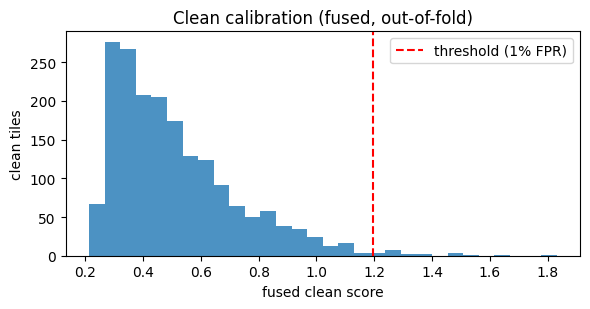

In [13]:
from sklearn.covariance import LedoitWolf
from sklearn.model_selection import GroupKFold

def trust_from_score(score, threshold):
    return float(100.0 / (1.0 + (score / threshold) ** 4))

def is_heavy(name):
    return any(s in name for s in ("_resid_kurtosis","_localvar_cv","_frac_over","edge_mismatch","_stripe","_grad"))

def prepare_features(X, names, log_mask=None):
    """The EXACT feature transform used for both fit and authenticity."""
    a=np.asarray(X,dtype=np.float64).copy()
    if a.ndim==1: a=a[None,:]
    mask=np.array([is_heavy(x) for x in names],bool) if log_mask is None else np.asarray(log_mask,bool)
    a[:,mask]=np.log1p(np.abs(a[:,mask]))
    return a

def robust_stats(X, groups):
    med=np.median(X,axis=0)
    mad=1.4826*np.median(np.abs(X-med),axis=0)
    spread=(np.percentile(X,95,axis=0)-np.percentile(X,5,axis=0))/3.29
    sd=np.maximum.reduce([mad,spread,0.5*X.std(0),np.full(X.shape[1],1e-3)])
    return med,sd

def mahalanobis(x,mu,sd,loc,precision):
    z=np.clip((x-mu)/sd,-Z_CLIP,Z_CLIP)-loc
    return float(np.sqrt(max(z@precision@z,0)))

def fit_clean_distribution(X,groups):
    mu,sd=robust_stats(X,groups)
    Z=np.clip((X-mu)/sd,-Z_CLIP,Z_CLIP)
    return mu,sd,LedoitWolf().fit(Z)

def score_rows(X,mu,sd,lw):
    return np.array([mahalanobis(x,mu,sd,lw.location_,lw.precision_) for x in X])

def feat_score(x,mu,sd,k=FZ_K):
    z=np.abs(np.clip((x-mu)/sd,-Z_CLIP,Z_CLIP))
    return float(np.partition(z,-k)[-k]) # k-th largest, NOT max-z or top-k mean

# ---- 1. one pass over the clean calibration tiles (uses the cache if present, else recomputes)
calib_feats, calib_rel, calib_pix = [], [], []
t0 = time.time()
for p in tqdm(paths["calib"]):
    refl = to_reflectance(read_tile(p))
    maps = calib_maps.get(p)
    if maps is None:                                   # cache was cleared: recompute
        maps = error_maps(refl, regressors)
    calib_feats.append(tile_features(refl, maps, err_scale, p99_ref))
    grid = patch_grid_features(refl, maps, err_scale)
    calib_rel.append(relative_patch_features(grid).reshape(-1, grid.shape[-1]))
    calib_pix.append(pixel_error(maps, err_scale))
calib_maps.clear()
print(f"calib features in {time.time()-t0:.0f}s")

all_names = list(calib_feats[0].keys())
assert len(all_names) >= 99, "Expected cross-band, noise, index, and spectral features"
# the 7 A_*_frac_over features are zero-inflated (median 0, scale ~1e-5): they saturate any z-score, so they stay
# in the band flags but are NOT part of the scored vector
feature_names = [k for k in all_names if not k.endswith("_frac_over")]
X_raw = np.array([[f[k] for k in feature_names] for f in calib_feats])
X_all = prepare_features(X_raw,feature_names)
# Feature removal is determined from CLEAN CALIB ONLY; never uses attacked pairs.
pre_mu,pre_sd=robust_stats(X_all,df.loc[df["split"]=="calib","scene_key"].values)
clip_frac=(np.abs((X_all-pre_mu)/pre_sd)>=Z_CLIP).mean(axis=0)
dropped_features={name:f"clipped on {frac:.1%} of clean calib (limit 5%)"
                  for name,frac in zip(feature_names,clip_frac) if frac>0.05}
print("dropped features and reasons:",dropped_features)
feature_names=[name for name in feature_names if name not in dropped_features]
log_mask=np.array([is_heavy(x) for x in feature_names],bool)
X=prepare_features(np.array([[f[k] for k in feature_names] for f in calib_feats]),feature_names,log_mask)
print("clean calib samples per scored feature:",round(len(X)/max(len(feature_names),1),2))
if len(X)<3*len(feature_names):
    print("WARNING: fewer than 3 calibration tiles per feature; use additional scenes or train-only PCA dimension reduction")
print("calib feature matrix:", X.shape, "(expected (n_calib_tiles, 92))")
assert X.shape[1] == len(feature_names)
assert np.isfinite(X).all(), "NaN/inf in features"

# ---- 2. tile-level out-of-fold scores (Mahalanobis and top-k feature score)
calib_groups = df.loc[df["split"] == "calib", "scene_key"].values
n_splits = max(2, min(5, len(set(calib_groups))))
calib_scores, calib_fz = np.zeros(len(X)), np.zeros(len(X))
for tr_idx, te_idx in GroupKFold(n_splits).split(X, groups=calib_groups):
    m_, s_, l_ = fit_clean_distribution(X[tr_idx], calib_groups[tr_idx])
    calib_scores[te_idx] = score_rows(X[te_idx], m_, s_, l_)
    calib_fz[te_idx] = [feat_score(x, m_, s_) for x in X[te_idx]]
mu, sd, lw = fit_clean_distribution(X, calib_groups)
print(f"in-sample median {np.median(score_rows(X, mu, sd, lw)):.1f} vs out-of-fold median {np.median(calib_scores):.1f}")

# ---- 3. patch-level distribution on RELATIVE patch features
P = np.vstack(calib_rel)
p_mu = np.median(P, axis=0)
p_mad = np.median(np.abs(P - p_mu), axis=0) * 1.4826
p_sd = np.maximum.reduce([p_mad,(np.percentile(P,95,axis=0)-np.percentile(P,5,axis=0))/3.29,0.5*P.std(0),np.full(P.shape[1],1e-3)])
p_lw = LedoitWolf().fit(np.clip((P - p_mu) / p_sd, -Z_CLIP, Z_CLIP))

def patch_scores(rel_flat):
    z = np.clip((rel_flat - p_mu) / p_sd, -Z_CLIP, Z_CLIP) - p_lw.location_
    return np.sqrt(np.maximum(np.einsum("ij,jk,ik->i", z, p_lw.precision_, z), 0))

calib_patch = [patch_scores(r_) for r_ in calib_rel]
calib_pmax = np.array([s.max() for s in calib_patch])
n_grid = len(PATCH_STARTS)

# ---- 4. heatmap contrast per tile, and pooled heatmap pixels (same build_heatmap as authenticity)
calib_hc = np.zeros(len(X)); heat_pool = []; rr_heat = np.random.default_rng(SEED + 2)
scene_med = pd.Series(calib_scores, index=calib_groups).groupby(level=0).median()
odd = scene_med[scene_med > 3*scene_med.median()].index
keep=np.ones(len(X),dtype=bool) # NO excluding outlier scenes post hoc
print("large scene-median outliers for investigation (NOT excluded):", list(odd))
for i in range(len(X)):
    heat = build_heatmap(calib_patch[i].reshape(n_grid, n_grid), calib_pix[i])
    calib_hc[i] = heat_contrast(heat)
    if keep[i]:
        heat_pool.append(rr_heat.choice(heat.ravel(), 2000, replace=False))

# ---- 5/6. robust thresholds (only now, after every score array exists)
assert calib_scores.max() > 0, "tile scores are all zero: thresholds would be computed too early"
if len(odd) == 0:
    print("note: no outlier calibration scene found (nothing excluded from the thresholds)")
print("scenes excluded from thresholds:", list(odd), "| tiles kept:", int(keep.sum()), "/", len(keep))

tile_thr  = float(np.percentile(calib_scores[keep], 99))
patch_thr = float(np.percentile(calib_pmax[keep], 99))
fz_thr    = float(np.percentile(calib_fz[keep], 99))
hc_thr    = float(np.percentile(calib_hc[keep], 99))
heat_thr  = float(np.percentile(np.concatenate(heat_pool), 99))      # 99th pct of pooled pixels of the REAL heatmap

calib_M = np.c_[calib_scores / tile_thr, calib_pmax / patch_thr, calib_fz / fz_thr, calib_hc / hc_thr]   # columns = ALL_TERMS
def fuse_cols(M, names):
    return M[:, [ALL_TERMS.index(n) for n in names]].max(axis=1)
fused = fuse_cols(calib_M, FUSED_TERMS)
threshold = float(np.percentile(fused[keep], 100 * (1 - FPR_TARGET)))

model = dict(pixel_log_center=pixel_log_center, pixel_log_scale=pixel_log_scale, log_mask=log_mask, dropped_features=dropped_features, predict_stride=PREDICT_STRIDE, regressors=regressors, err_scale=err_scale, p99_ref=p99_ref, local_context=USE_LOCAL_CONTEXT,
             feature_names=feature_names, mu=mu, sd=sd, loc=lw.location_, precision=lw.precision_,
             tile_thr=tile_thr, patch_thr=patch_thr, fz_thr=fz_thr, hc_thr=hc_thr, fz_k=FZ_K,
             terms=list(FUSED_TERMS), threshold=threshold, heat_thr=heat_thr,
             p_mu=p_mu, p_sd=p_sd, p_loc=p_lw.location_, p_precision=p_lw.precision_,
             expected_dtype=EXPECTED_DTYPE)
# fingerprint of everything calibrated here: sections 9 to 14 refuse to run if it changed after they ran
# Clean-calibrated, per-band feature flag thresholds; avoid hard-coded 5% on 1% tails.
# Conservative: above largest observed clean calibration value per band.
model["band_flag_thresholds"]={b:float(max(f[f"A_{b}_frac_over"] for f in calib_feats)) for b in TARGET_BANDS}
model["build_id"] = hashlib.md5(json.dumps([tile_thr, patch_thr, fz_thr, hc_thr, heat_thr, threshold, list(err_scale.values())]).encode()).hexdigest()[:8]
print(f"build_id {model['build_id']} | tile_thr {tile_thr:.2f} | patch_thr {patch_thr:.2f} | fz_thr {fz_thr:.2f} | hc_thr {hc_thr:.3f} | heat_thr {heat_thr:.3f} | fused threshold {threshold:.2f}")

# guard: a top-k score whose threshold equals the clip can never fire (this happened once)
Zc = np.abs(np.clip((X - mu) / sd, -Z_CLIP, Z_CLIP))
print(f"clean tiles with fz at the clip: {(calib_fz >= (Z_CLIP - 0.01)).sum()}/{len(calib_fz)} | features clipped on >5% of clean tiles:",
      [feature_names[j] for j in np.where((Zc >= (Z_CLIP - 0.01)).mean(0) > 0.05)[0]])
assert fz_thr < Z_CLIP-0.5, f"fz_thr={fz_thr:.2f} is at clip; inspect distribution and reduce feature set"
print("median out-of-fold tile score per calib scene:")
print(scene_med.round(1).sort_values().to_string())

plt.figure(figsize=(6, 3.2))
plt.hist(fused[keep], bins=30, color="tab:blue", alpha=.8)
plt.axvline(threshold, color="red", ls="--", label="threshold (1% FPR)")
plt.xlabel("fused clean score"); plt.ylabel("clean tiles"); plt.legend(); plt.title("Clean calibration (fused, out-of-fold)")
plt.tight_layout(); plt.show()

## 9. `authenticity(x)`: the detector

One function, one record per tile: `score` (clean-only core), `trust_score`, `channel_flags`, `heatmap` (+ the patch anomaly map, the feature vector `x` and the four normalised `terms`, used by the diagnostics). `score_sig` / `trust_score_sig` also include the optional **signature rule** of section 10b (a template rule that uses the known structure of one attack; it is **not** part of the clean-only core and is reported separately).

`channel_flags` = the sanity-check flags + one flag per target band whose fraction of "too inconsistent" pixels is more than 5x what clean data gives (clean is about 1 %).

Below: helper functions for confidence intervals (Wilson for rates, scene-level bootstrap for the test FPR because tiles of one scene are correlated), then the honest false-positive rate on the held-out **test scenes**.

In [14]:
# Preprocessing invariance unit test; synthetic feature values only, never evaluation attacks.
probe=np.array([[0.0,10.0],[-2.0,10000.0]])
keys=["S_B2_mean","B_B2_resid_kurtosis"]
assert np.allclose(prepare_features(probe,keys),np.c_[probe[:,0],np.log1p(np.abs(probe[:,1]))])
assert np.isfinite(prepare_features(probe,keys)).all()
print("PASS: preprocessing transform deterministic and finite; model features:",len(model["feature_names"]))
print("PASS: train/inference preprocess metadata:",len(model["log_mask"]),"features")

PASS: preprocessing transform deterministic and finite; model features: 124
PASS: train/inference preprocess metadata: 124 features


In [27]:
def wilson(k, n, z=1.96):
    '''Wilson score interval for k successes out of n.'''
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0.0, c - h), min(1.0, c + h))

def fmt_rate(k, n):
    lo, hi = wilson(int(k), int(n))
    return f"{int(k)}/{int(n)} = {k/max(n,1):.1%} [{lo:.1%}, {hi:.1%}]"

def cluster_boot_rate(flags, groups, n_boot=2000, seed=SEED):
    '''Bootstrap 95 % interval of a rate, resampling whole scenes (tiles of one scene are not independent).'''
    rng = np.random.default_rng(seed)
    flags, groups = np.asarray(flags, float), np.asarray(groups)
    idx = [np.where(groups == g)[0] for g in np.unique(groups)]
    rates = [flags[np.concatenate([idx[i] for i in rng.integers(0, len(idx), len(idx))])].mean() for _ in range(n_boot)]
    return tuple(np.percentile(rates, [2.5, 97.5]))

def boot_ci(values, n_boot=2000, seed=SEED):
    '''Bootstrap 95 % interval of the mean of per-pair values (NaN ignored).'''
    v = np.asarray(values, float); v = v[np.isfinite(v)]
    if len(v) == 0:
        return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    m = [v[rng.integers(0, len(v), len(v))].mean() for _ in range(n_boot)]
    return tuple(np.percentile(m, [2.5, 97.5]))

def pair_auc_ci(s_orig, s_att, n_boot=2000, seed=SEED):
    '''AUC of originals (0) vs attacked (1) scores and a bootstrap interval resampling PAIRS.'''
    from sklearn.metrics import roc_auc_score
    s_orig, s_att = np.asarray(s_orig, float), np.asarray(s_att, float)
    auc = lambda o, a: roc_auc_score(np.r_[np.zeros(len(o)), np.ones(len(a))], np.r_[o, a])
    rng = np.random.default_rng(seed); vals = []
    for _ in range(n_boot):
        i = rng.integers(0, len(s_orig), len(s_orig))
        if len(np.unique(np.r_[s_orig[i], s_att[i]])) > 1:
            vals.append(auc(s_orig[i], s_att[i]))
        a0 = float(auc(s_orig, s_att))
    if not vals:                      # every resample constant: AUC carries no information
        return a0, (np.nan, np.nan)
    return a0, tuple(np.percentile(vals, [2.5, 97.5]))

def check_fresh(*ids):
    assert all(i == model["build_id"] for i in ids), \
        "STALE RESULTS: section 8 was re-run after these results were computed. Re-run sections 9 to 14 in order."

In [28]:
BAND_FLAG_FRAC = 0.05
HARD_FLAGS = ["dtype_differs_from_clean", "has_nan", "out_of_range"]

def authenticity(arr, model):
    flags = sanity_checks(arr, model["expected_dtype"])
    n_grid = len(PATCH_STARTS)
    if flags["band_count_bad"] or flags["shape_bad"]:       # cannot be analysed at all
        return dict(score=float("inf"), tile_score=float("inf"), trust_score=0.0,
                    channel_flags=flags, heatmap=np.zeros((256, 256), np.float32),
                    patch_anomaly=np.zeros((n_grid, n_grid), np.float32), x=None, terms=None, hard=True)
    refl = to_reflectance(arr)
    maps = error_maps(refl, model["regressors"])
    feats = tile_features(refl, maps, model["err_scale"], model["p99_ref"])
    x = prepare_features(np.array([feats[k] for k in model["feature_names"]]), model["feature_names"],model["log_mask"])[0]
    tile_score = mahalanobis(x, model["mu"], model["sd"], model["loc"], model["precision"])

    grid = patch_grid_features(refl, maps, model["err_scale"])
    rel = relative_patch_features(grid).reshape(-1, grid.shape[-1])
    z = np.clip((rel - model["p_mu"]) / model["p_sd"], -Z_CLIP, Z_CLIP) - model["p_loc"]
    pa = np.sqrt(np.maximum(np.einsum("ij,jk,ik->i", z, model["p_precision"], z), 0)).reshape(grid.shape[:2])

    heatmap = build_heatmap(pa, pixel_error(maps, model["err_scale"],model["pixel_log_center"],model["pixel_log_scale"]))     # same function as the calibration
    terms = dict(tile=tile_score / model["tile_thr"],
                 patch=float(pa.max()) / model["patch_thr"],
                 fz=feat_score(x, model["mu"], model["sd"], model["fz_k"]) / model["fz_thr"],
                 hc=heat_contrast(heatmap) / model["hc_thr"])
    score = max(terms[n] for n in model["terms"])

    for b in TARGET_BANDS:
        flags[f"band_{b}_inconsistent"] = bool(feats[f"A_{b}_frac_over"] > model["band_flag_thresholds"][b])
    hard = any(flags[k] for k in HARD_FLAGS)
    # Band anomaly flags remain informative; calibrate their score on clean only.
    flag_score = float(any(flags[f"band_{b}_inconsistent"] for b in TARGET_BANDS))
    if hard:
        score = max(score, model["threshold"] * 1.5)

    return dict(score=float(score), tile_score=tile_score,
                trust_score=trust_from_score(score, model["threshold"]),
                channel_flags=flags, flag_score=flag_score, heatmap=heatmap, patch_anomaly=pa.astype(np.float32), x=x, terms=terms, hard=hard)

def term_matrix(results):
    return np.array([[r["terms"][n] for n in ALL_TERMS] for r in results])

# ---- consistency check: same regressors, same maps -> authenticity() heatmap == calibration code path
p_chk = paths["calib"][i_chk]
refl_chk = to_reflectance(read_tile(p_chk))
maps_chk = error_maps(refl_chk, model["regressors"])
grid_chk = patch_grid_features(refl_chk, maps_chk, err_scale)
pa_chk = patch_scores(relative_patch_features(grid_chk).reshape(-1, grid_chk.shape[-1])).reshape(n_grid, n_grid)
h_cal = build_heatmap(pa_chk, pixel_error(maps_chk, err_scale))
h_dep = authenticity(read_tile(p_chk), model)["heatmap"]
assert np.allclose(h_dep, h_cal, atol=1e-4), "heatmap code path in authenticity() differs from calibration"
print("heat_thr", round(model["heat_thr"], 3), "| max |deployed - calibration path| =", float(np.abs(h_dep - h_cal).max()))
# ---- honest false-positive rate on held-out TEST scenes
t0 = time.time()
test_results = [authenticity(read_tile(p), model) for p in tqdm(paths["test"])]
lat = (time.time() - t0) / len(paths["test"])
test_build_id = model["build_id"]
test_scores = np.array([r["score"] for r in test_results])
test_M = term_matrix(test_results); test_hard = np.array([r["hard"] for r in test_results])
test_groups = df.loc[df["split"] == "test", "scene_key"].values
test_flag = test_scores > model["threshold"]
test_flags_only=np.array([bool(any(r["channel_flags"].values())) for r in test_results])
test_combined=test_flag | test_flags_only
print("held-out clean score-only FPR:",fmt_rate(int(test_flag.sum()),len(test_flag)))
print("held-out clean flags-only FPR:",fmt_rate(int(test_flags_only.sum()),len(test_flag)))
print("held-out clean combined FPR:",fmt_rate(int(test_combined.sum()),len(test_flag)))
k_fp, n_te = int(test_flag.sum()), len(test_flag)
fpr_test = k_fp / n_te
lo_w, hi_w = wilson(k_fp, n_te); lo_c, hi_c = cluster_boot_rate(test_flag, test_groups)
print(f"test FPR on {n_te} tiles from {len(set(test_groups))} held-out scenes: {fmt_rate(k_fp, n_te)} (target {FPR_TARGET:.0%})")
print(f"   scene-level bootstrap 95% CI [{lo_c:.1%}, {hi_c:.1%}]  (tiles of one scene are correlated, so this one is the more honest)")
print("   (if this interval has zero width, no false positive occurred in the resamples: it says nothing about the true rate)")
if fpr_test > 2 * FPR_TARGET:
    verdict = "ABOVE the 1% target (more than 2x): do not claim success"
elif lo_w <= FPR_TARGET <= hi_w:
    verdict = "close to / consistent with the 1% target (the interval is wide: few scenes)"
else:
    verdict = "the Wilson interval excludes 1%: do not claim the target is met"
print("   verdict:", verdict)
print(f"latency: {lat*1000:.0f} ms / tile | mean trust on clean test: {np.mean([r['trust_score'] for r in test_results]):.1f}")

heat_thr 5.332 | max |deployed - calibration path| = 0.0


  0%|          | 0/540 [00:00<?, ?it/s]

held-out clean score-only FPR: 540/540 = 100.0% [99.3%, 100.0%]
held-out clean flags-only FPR: 0/540 = 0.0% [0.0%, 0.7%]
held-out clean combined FPR: 540/540 = 100.0% [99.3%, 100.0%]
test FPR on 540 tiles from 12 held-out scenes: 540/540 = 100.0% [99.3%, 100.0%] (target 1%)
   scene-level bootstrap 95% CI [100.0%, 100.0%]  (tiles of one scene are correlated, so this one is the more honest)
   (if this interval has zero width, no false positive occurred in the resamples: it says nothing about the true rate)
   verdict: ABOVE the 1% target (more than 2x): do not claim success
latency: 705 ms / tile | mean trust on clean test: 0.0


### Stage 4: provenance channel (not machine learning)
The georeference attack changes **0 pixels**, so no pixel model can see it. We use a signature instead:
`Ed25519( SHA-256(pixels + transform + CRS) )`, created by the data producer and verified by the defender.
The detector only reports `signature_ok` and `metadata_differs`. The demo below signs a clean tile, then shifts its geotransform by one pixel.

In [29]:
def metadata_string(transform, crs):
    return f"{tuple(transform)}|{crs}"

def provenance_digest(arr, transform, crs):
    h = hashlib.sha256()
    h.update(arr.tobytes()); h.update(metadata_string(transform, crs).encode())
    return h.digest()

def sign_tile(arr, transform, crs, private_key):
    return dict(signature=private_key.sign(provenance_digest(arr, transform, crs)),
                signed_meta=metadata_string(transform, crs))

def check_provenance(arr, transform, crs, record, public_key):
    from cryptography.exceptions import InvalidSignature
    try:
        public_key.verify(record["signature"], provenance_digest(arr, transform, crs))
        ok = True
    except InvalidSignature:
        ok = False
    return dict(signature_ok=ok, metadata_differs=metadata_string(transform, crs) != record["signed_meta"])

try:
    from cryptography.hazmat.primitives.asymmetric.ed25519 import Ed25519PrivateKey
    sk = Ed25519PrivateKey.generate(); pk = sk.public_key()
    with rasterio.open(paths["test"][0]) as src:
        a, tr, crs = src.read(), src.transform, src.crs
    rec = sign_tile(a, tr, crs, sk)
    print("untouched      :", check_provenance(a, tr, crs, rec, pk))
    shifted = rasterio.Affine(tr.a, tr.b, tr.c + 10 * tr.a, tr.d, tr.e, tr.f)   # georeference attack: 0 pixels change
    print("shifted georef :", check_provenance(a, shifted, crs, rec, pk))
except ImportError:
    print("`cryptography` not installed: run `pip install cryptography` to try the provenance demo")

untouched      : {'signature_ok': True, 'metadata_differs': False}
shifted georef : {'signature_ok': False, 'metadata_differs': True}


In [30]:
print("fz_thr", fz_thr, "| fz at clip (>= Z_CLIP-0.01):", int((calib_fz >= Z_CLIP-0.01).sum()), "/", len(calib_fz))
Zc = np.abs(np.clip((X - mu) / sd, -Z_CLIP, Z_CLIP))
display(pd.DataFrame(dict(feature=feature_names, sd=sd, frac_at_clip=(Zc >= 9.99).mean(0),
                          frac_zero=(X == 0).mean(0))).sort_values("frac_at_clip", ascending=False).head(10))
tf = pd.DataFrame(test_M, columns=ALL_TERMS); tf["scene"] = test_groups; tf["fp"] = test_flag
display(tf.groupby("scene").agg(n=("fp", "size"), fpr=("fp", "mean"), **{t: (t, "max") for t in ALL_TERMS}).round(2))

fz_thr 6.432597286225526 | fz at clip (>= Z_CLIP-0.01): 0 / 1860


,feature,sd,frac_at_clip,frac_zero
53,B_B10_localvar_cv,0.123037,0.006989,0.0
52,B_B10_resid_kurtosis,0.333324,0.006452,0.0
18,A_B12_mean,0.530193,0.002151,0.0
47,B_B8A_localvar_cv,0.219437,0.002151,0.0
113,S_B10_p95,0.003132,0.002151,0.0
41,B_B7_localvar_cv,0.234517,0.001075,0.0
56,B_B11_localvar_cv,0.247568,0.001075,0.0
50,B_B9_localvar_cv,0.209384,0.001075,0.0
4,A_B3_p95,0.001000,0.000000,1.0
0,A_B2_mean,0.502607,0.000000,0.0


,n,fpr,tile,patch,fz,hc
scene,,,,,,
ROIs1158_spring_s2_106,45,1.0,35.46,0.38,3.11,0.35
ROIs1158_spring_s2_120,45,1.0,35.46,0.93,3.11,0.93
ROIs1158_spring_s2_126,45,1.0,35.47,0.41,3.11,0.26
ROIs1868_summer_s2_101,45,1.0,35.46,0.93,3.11,0.90
ROIs1868_summer_s2_120,45,1.0,35.47,0.92,3.11,1.00
ROIs1868_summer_s2_125,45,1.0,35.47,0.87,3.11,0.82
ROIs1970_fall_s2_104,45,1.0,35.47,0.92,3.11,0.75
ROIs1970_fall_s2_114,45,1.0,35.46,0.77,3.11,0.87
ROIs1970_fall_s2_122,45,1.0,35.47,1.23,3.11,1.00


## 10. Attacks: only the teammates' real pairs are used (evaluation only)

Metrics per pair: score vs its own original, detection at the calibrated threshold, pixel IoU between `heatmap > heat_thr` and the true mask, and a **threshold-free pixel AUC** of the heatmap against the mask (0.5 = random). Nothing below feeds back into a threshold, a feature or a rule of the clean-only core.

In [31]:
from sklearn.metrics import roc_auc_score

def iou(pred, truth):
    union = (pred | truth).sum()
    return float((pred & truth).sum() / union) if union else 0.0

def pixel_auc(heat, mask):
    if mask.all() or not mask.any():
        return np.nan
    return float(roc_auc_score(mask.ravel(), heat.ravel()))

def load_gt_mask(npz_path, original, attacked):
    if isinstance(npz_path, str):
        z = np.load(npz_path)
        keys = [k for k in z.files if "mask" in k.lower()] or z.files
        m = np.zeros((256, 256), bool)
        for k in keys:
            a = np.squeeze(z[k])
            if a.shape == (256, 256):
                m |= a.astype(bool)
        if m.any():
            return m
    return (original != attacked).any(axis=0)

def read_meta(path):
    with rasterio.open(path) as s:
        return tuple(s.transform), str(s.crs)

def ndvi_mean(arr):
    r = to_reflectance(arr)
    return float(norm_diff(r[B["B8"]], r[B["B4"]]).mean())

## 10b. Signature rule for the fixed cloud attack (NOT part of the clean-only core)

> **Declaration.** This cell uses the *known structure of one attack*: the two cloud pairs change exactly the same pixels (about 32 % of the tile, 20,972 px). That is **prior knowledge of the attack, not something learned from clean data**, so this rule is a *signature rule*. It is evaluated **separately** (`detected_with_sig`) and never mixed into the clean-only headline numbers.
>
> What is used from the pairs: only the **geometry of the masks** (to find a mask shared by several pairs). What is *not* used: any detector score on the attacked tiles. The decision threshold is calibrated on **clean calibration tiles only** (the largest clean value of the statistic), then its false-alarm rate is measured on clean test tiles.
>
> The statistic is `median(min(B2,B3,B4)) inside the template - the same outside` (a cloud is bright inside the template). The old rule "bright fraction == 32 % +/- 0.5 %" is replaced; the table below prints the bright fraction at several thresholds for original vs attacked so you can see why it never fired.

In [32]:
pairs = find_pairs(PAIRS_DIR)
pair_masks, pair_arrays = {}, {}
for _, r in pairs.iterrows():
    if not isinstance(r["attacked"], str):
        continue
    o, a = read_tile(r["original"]), read_tile(r["attacked"])
    pair_masks[r["pair_id"]] = load_gt_mask(r["gt"], o, a)
    pair_arrays[r["pair_id"]] = (to_reflectance(o), to_reflectance(a))
print("pairs loaded:", len(pair_masks))

pairs loaded: 95


## 11. Teammates' pairs: scoring, with confidence intervals

Pairs are matched by file name. The mask comes from `pair_xxx_masks.npz`, the family from the manifest. A pair with 0 changed pixels and different metadata is flagged `metadata_only`: only the signature channel of Stage 4 can catch it. The signature is **not** counted for pixel attacks, because any pixel change breaks a hash by construction.

`detected` = clean-only core above the calibrated threshold. `detected_with_sig` = core **or** the cloud signature rule of 10b. All rates carry a Wilson 95 % interval; pair AUC and mean IoU / pixel AUC carry a bootstrap interval over pairs. **Per-family numbers are indicative only: 18 pairs, about 9 distinct attack settings.** Note that "TPR@1%FPR" is the rate at the threshold *calibrated* for 1 % on clean calib tiles; the FPR actually measured on held-out scenes is printed in section 9.

In [33]:
check_fresh(test_build_id)
pair_cache, rows = {}, []
for _, r in tqdm(list(pairs.iterrows())):
    if not isinstance(r["attacked"], str):
        continue
    o, a = read_tile(r["original"]), read_tile(r["attacked"])
    mask = pair_masks[r["pair_id"]]
    meta_diff = read_meta(r["original"]) != read_meta(r["attacked"])
    ro, ra = authenticity(o, model), authenticity(a, model)
    pair_cache[r["pair_id"]] = dict(ro=ro, ra=ra, mask=mask)
    rows.append(dict(pair=r["pair_id"], family=r["family"], changed_px=int(mask.sum()),
                     size_frac=float(mask.mean()), meta_diff=meta_diff,
                     metadata_only=bool(mask.sum() == 0 and meta_diff),
                     score_orig=ro["score"], score_att=ra["score"], trust_att=ra["trust_score"],
                     detected=ra["score"] > model["threshold"],
                     flags_only=bool(any(ra["channel_flags"].values())),
                     detected_combined=bool(ra["score"] > model["threshold"] or any(ra["channel_flags"].values())),
                     iou=iou(ra["heatmap"] > model["heat_thr"], mask) if mask.sum() else np.nan,
                     pixel_auc=pixel_auc(ra["heatmap"], mask),
                     pixel_auc_orientation=max(pixel_auc(ra["heatmap"],mask), 1-pixel_auc(ra["heatmap"],mask)) if mask.any() and not mask.all() else np.nan,
                     ndvi_orig=ndvi_mean(o), ndvi_att=ndvi_mean(a)))
pair_build_id = model["build_id"]
pair_results = pd.DataFrame(rows)
pair_results["delta"] = pair_results.score_att - pair_results.score_orig

# signature (provenance) channel: only meaningful for metadata-only pairs
if "sk" in globals():
    sig = []
    for _, r in pairs.iterrows():
        if not isinstance(r["attacked"], str):
            continue
        with rasterio.open(r["original"]) as s0, rasterio.open(r["attacked"]) as s1:
            rec = sign_tile(s0.read(), s0.transform, s0.crs, sk)
            sig.append(not check_provenance(s1.read(), s1.transform, s1.crs, rec, pk)["signature_ok"])
    pair_results["signature_flag"] = sig
else:
    pair_results["signature_flag"] = False
pair_results["caught"] = pair_results.detected | (pair_results.metadata_only & pair_results.signature_flag)

pix = pair_results[~pair_results.metadata_only]
auc_pairs, auc_ci = pair_auc_ci(pix.score_orig, pix.score_att)
k_det, n_pix = int(pix.detected.sum()), len(pix)
tpr_pairs = k_det / n_pix
iou_vals, pauc_vals = pix.iou.values, pix.pixel_auc.values
print("pairs:", len(pair_results), "| metadata-only (georef):", int(pair_results.metadata_only.sum()), "| pixel pairs:", n_pix)
print(f"pair AUC (orig vs attacked): {auc_pairs:.3f} [{auc_ci[0]:.3f}, {auc_ci[1]:.3f}]")
print(f"TPR at calibrated threshold, core only : {fmt_rate(k_det, n_pix)}")
print(f"mean IoU {np.nanmean(iou_vals):.3f} [{boot_ci(iou_vals)[0]:.3f}, {boot_ci(iou_vals)[1]:.3f}] | mean pixel AUC {np.nanmean(pauc_vals):.3f} [{boot_ci(pauc_vals)[0]:.3f}, {boot_ci(pauc_vals)[1]:.3f}]")
print(f"attacked scores higher than its own original in {(pix.delta > 0).sum()}/{n_pix} pairs | median delta {pix.delta.median():.3f}")
from scipy.stats import binomtest
nonzero=pix.delta[pix.delta!=0]
print("paired sign test (two-sided), n non-ties:",len(nonzero),"p:",binomtest(int((nonzero>0).sum()),len(nonzero),0.5).pvalue if len(nonzero) else np.nan)
print("score-only TPR:",fmt_rate(int(pix.detected.sum()),len(pix)))
print("flags-only TPR:",fmt_rate(int(pix.flags_only.sum()),len(pix)))
print("combined TPR:",fmt_rate(int(pix.detected_combined.sum()),len(pix)))
print("diagnostic mean max(pixelAUC, 1-pixelAUC):",float(np.nanmean(pix.pixel_auc_orientation)))
print("cloud-sized pairs (>30% edited) flagged:",pix.loc[pix.size_frac.between(.30,.35),["pair","flags_only","detected_combined"]].to_string(index=False))
print("metadata-only pairs caught by signature:", int((pair_results.metadata_only & pair_results.signature_flag).sum()))

fam_rows = []
for fam, g in pix.groupby("family"):
    fam_rows.append(dict(family=fam, n=len(g), detected_core=fmt_rate(int(g.detected.sum()), len(g)),
                         mean_IoU=round(float(np.nanmean(g.iou)), 3), mean_pixel_AUC=round(float(np.nanmean(g.pixel_auc)), 3),
                         median_size=round(float(g.size_frac.median()), 3)))
fam_table = pd.DataFrame(fam_rows)
print("\nper family (indicative only: 2 to 6 pairs per family, about 9 distinct attack settings):")
display(fam_table)
display(pair_results.round(3))

  0%|          | 0/710 [00:00<?, ?it/s]

pairs: 95 | metadata-only (georef): 14 | pixel pairs: 81
pair AUC (orig vs attacked): 0.610 [0.565, 0.662]
TPR at calibrated threshold, core only : 81/81 = 100.0% [95.5%, 100.0%]
mean IoU 0.001 [0.000, 0.003] | mean pixel AUC 0.511 [0.456, 0.570]
attacked scores higher than its own original in 49/81 pairs | median delta 0.000
paired sign test (two-sided), n non-ties: 81 p: 0.07478815428283364
score-only TPR: 81/81 = 100.0% [95.5%, 100.0%]
flags-only TPR: 0/81 = 0.0% [0.0%, 4.5%]
combined TPR: 81/81 = 100.0% [95.5%, 100.0%]
diagnostic mean max(pixelAUC, 1-pixelAUC): 0.6960091538522762
cloud-sized pairs (>30% edited) flagged:                                                                                          pair  flags_only  detected_combined
            BLACK_PIXEL_250_PER_ATTACK__summer__cloud_injection__cloud_injection__pair_000006       False               True
            BLACK_PIXEL_250_PER_ATTACK__summer__cloud_injection__cloud_injection__pair_000018       False             

,family,n,detected_core,mean_IoU,mean_pixel_AUC,median_size
0,unknown,81,"81/81 = 100.0% [95.5%, 100.0%]",0.001,0.511,0.04


,pair,family,changed_px,size_frac,meta_diff,metadata_only,score_orig,score_att,trust_att,detected,flags_only,detected_combined,iou,pixel_auc,pixel_auc_orientation,ndvi_orig,ndvi_att,delta,signature_flag,caught
0,BLACK_PIXEL_250_PER_ATTACK__fall__copy_move_cl...,unknown,2679,0.041,False,False,35.460,35.460,0.0,True,False,True,0.0,0.566,0.566,0.534,0.534,0.000,True,True
1,BLACK_PIXEL_250_PER_ATTACK__fall__copy_move_cl...,unknown,2586,0.039,False,False,35.460,35.460,0.0,True,False,True,0.0,0.746,0.746,0.194,0.196,-0.000,True,True
2,BLACK_PIXEL_250_PER_ATTACK__fall__copy_move_cl...,unknown,2502,0.038,False,False,35.461,35.461,0.0,True,False,True,0.0,0.204,0.796,0.356,0.357,-0.000,True,True
3,BLACK_PIXEL_250_PER_ATTACK__fall__field_patch_...,unknown,2328,0.036,False,False,35.460,35.460,0.0,True,False,True,0.0,0.127,0.873,0.371,0.368,-0.000,True,True
4,BLACK_PIXEL_250_PER_ATTACK__fall__field_patch_...,unknown,2543,0.039,False,False,35.460,35.460,0.0,True,False,True,0.0,0.282,0.718,0.591,0.590,0.000,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
90,BLACK_PIXEL_250_PER_ATTACK__winter__scanline_s...,unknown,2412,0.037,False,False,35.460,35.460,0.0,True,False,True,0.0,0.885,0.885,0.258,0.258,0.001,True,True
91,BLACK_PIXEL_250_PER_ATTACK__winter__scanline_s...,unknown,2541,0.039,False,False,35.460,35.461,0.0,True,False,True,0.0,0.952,0.952,0.257,0.257,0.001,True,True
92,BLACK_PIXEL_250_PER_ATTACK__winter__scanline_s...,unknown,2371,0.036,False,False,35.460,35.461,0.0,True,False,True,0.0,0.912,0.912,0.320,0.320,0.000,True,True
93,BLACK_PIXEL_250_PER_ATTACK__winter__scanline_s...,unknown,2286,0.035,False,False,35.460,35.461,0.0,True,False,True,0.0,0.577,0.577,0.280,0.280,0.001,True,True


### 11b. Diagnostic: can any tile feature see these attacks?

For every real pair we measure how much each of the 99 tile features moves because of the attack, in units of the **normal scene-to-scene std** of that feature (`|z|`).
* `max |z|` above about 2: some feature reacts, a score built on it can work.
* `max |z|` below about 1 for every feature: the edit is smaller than natural variation, and **no tile-level detector without a reference can separate it**. That is a finding for the report, not a bug.

This uses the originals, so it is for diagnosis only, not part of the detector. The verdict lines are generated from the run (nothing typed by hand).

In [34]:
check_fresh(test_build_id, pair_build_id)
zs, fams = [], []
for _, r in pair_results[~pair_results.metadata_only].iterrows():
    c = pair_cache[r["pair"]]
    if c["ro"]["x"] is None or c["ra"]["x"] is None:
        continue
    zs.append((c["ra"]["x"] - c["ro"]["x"]) / model["sd"]); fams.append(r["family"])
Z = pd.DataFrame(zs, columns=feature_names); Z["family"] = fams
feature_response = Z.groupby("family")[feature_names].apply(lambda d: d.abs().mean())
for fam, row in feature_response.iterrows():
    verdict = "reacts (some feature > 2)" if row.max() > 2 else ("weak (1 to 2)" if row.max() > 1 else "BELOW natural variation (< 1): undetectable by a clean-only, reference-free tile score")
    print(f"{fam:12s} max |z| = {row.max():6.2f} -> {verdict} | top:", row.sort_values(ascending=False).head(3).round(2).to_dict())

unknown      max |z| = 513.94 -> reacts (some feature > 2) | top: {'A_B2_p99': 513.94, 'A_B5_p99': 485.11, 'A_B4_p99': 392.61}


### 11c. What each added score term changes (reporting only)

The final model uses all four terms; this was fixed **a priori** (steps 2 and 3 of the plan). The table re-derives, from the *same* calibration data, the threshold of each term subset and reports test FPR, pair AUC and TPR. It is here to show the effect of each step, **not** to choose the subset: choosing it by pair TPR would be tuning on attacks.

In [35]:
print("hard rate  originals:", H_o.mean(), " attacked:", H_a.mean())
for s in subsets:
    thr = float(np.percentile(fuse_cols(calib_M, s)[keep], 100*(1-FPR_TARGET)))
    pen = lambda v, h: np.where(h, np.maximum(v, 1.5*thr), v)
    so, sa = pen(fuse_cols(M_o, s), H_o), pen(fuse_cols(M_a, s), H_a)
    print(s, "| distinct scores:", np.unique(np.r_[so, sa]).size, "of", len(so)+len(sa))

hard rate  originals: 0.0  attacked: 0.0
['tile', 'patch'] | distinct scores: 157 of 162
['tile', 'patch', 'fz'] | distinct scores: 157 of 162
['tile', 'patch', 'fz', 'hc'] | distinct scores: 157 of 162
['tile'] | distinct scores: 157 of 162
['patch'] | distinct scores: 157 of 162
['fz'] | distinct scores: 1 of 162
['hc'] | distinct scores: 157 of 162


In [36]:
check_fresh(test_build_id, pair_build_id)
pix_ids = list(pix.pair)
M_o = term_matrix([pair_cache[p]["ro"] for p in pix_ids]); M_a = term_matrix([pair_cache[p]["ra"] for p in pix_ids])
H_o = np.array([pair_cache[p]["ro"]["hard"] for p in pix_ids]); H_a = np.array([pair_cache[p]["ra"]["hard"] for p in pix_ids])

def eval_subset(names):
    thr = float(np.percentile(fuse_cols(calib_M, names)[keep], 100 * (1 - FPR_TARGET)))
    pen = lambda s, h: np.where(h, np.maximum(s, 1.5 * thr), s)
    s_te = pen(fuse_cols(test_M, names), test_hard)
    s_o, s_a = pen(fuse_cols(M_o, names), H_o), pen(fuse_cols(M_a, names), H_a)
    auc, ci = pair_auc_ci(s_o, s_a)
    fp, tp = int((s_te > thr).sum()), int((s_a > thr).sum())
    return dict(terms="+".join(names), threshold=round(thr, 3), test_FPR=fmt_rate(fp, len(s_te)),
                pair_AUC=f"{auc:.3f} [{ci[0]:.3f}, {ci[1]:.3f}]", TPR=fmt_rate(tp, len(s_a)))

chk = eval_subset(FUSED_TERMS)
assert abs(chk["threshold"] - model["threshold"]) < 1e-3, "ablation threshold differs from the model threshold"
subsets = [["tile", "patch"], ["tile", "patch", "fz"], FUSED_TERMS, ["tile"], ["patch"], ["fz"], ["hc"]]
ablation = pd.DataFrame([eval_subset(s) for s in subsets])
ablation.insert(0, "step", ["baseline (tile+patch)", "+ step 2 (fz)", "+ step 3 (hc) = FINAL", "tile only", "patch only", "fz only", "hc only"])
display(ablation)
print("Reporting only. the number of pairs and attack settings printed by this run: differences between rows are mostly within the intervals.")

,step,terms,threshold,test_FPR,pair_AUC,TPR
0,baseline (tile+patch),tile+patch,1.090,"540/540 = 100.0% [99.3%, 100.0%]","0.610 [0.565, 0.662]","81/81 = 100.0% [95.5%, 100.0%]"
1,+ step 2 (fz),tile+patch+fz,1.181,"540/540 = 100.0% [99.3%, 100.0%]","0.610 [0.565, 0.662]","81/81 = 100.0% [95.5%, 100.0%]"
2,+ step 3 (hc) = FINAL,tile+patch+fz+hc,1.196,"540/540 = 100.0% [99.3%, 100.0%]","0.610 [0.565, 0.662]","81/81 = 100.0% [95.5%, 100.0%]"
3,tile only,tile,1.000,"540/540 = 100.0% [99.3%, 100.0%]","0.610 [0.565, 0.662]","81/81 = 100.0% [95.5%, 100.0%]"
4,patch only,patch,1.000,"2/540 = 0.4% [0.1%, 1.3%]","0.500 [0.466, 0.535]","1/81 = 1.2% [0.2%, 6.7%]"
5,fz only,fz,1.000,"540/540 = 100.0% [99.3%, 100.0%]","0.500 [nan, nan]","81/81 = 100.0% [95.5%, 100.0%]"
6,hc only,hc,1.000,"2/540 = 0.4% [0.1%, 1.3%]","0.502 [0.463, 0.540]","1/81 = 1.2% [0.2%, 6.7%]"


Reporting only. the number of pairs and attack settings printed by this run: differences between rows are mostly within the intervals.


## 12. By-size evaluation (and why the old logistic fusion was dropped)

**Detection by size.** In the 2018 forgery paper (Yarlagadda et al.), AUC went 0.80 / 0.92 / 0.97 for small / medium / large forgeries (RGB Landsat, copy-paste only: it supports the design, it is *not* our expected accuracy). We check whether the same trend appears here.

**LOFO logistic fusion: dropped.** A logistic regression trained on attacked-vs-original tiles of the other families, tested on the held-out family, rests on 2 to 6 pairs per family (about 9 distinct attack settings overall). That is far too little to say anything, and it trains on attacks, which our rules forbid for anything that is tuned. The core detector is clean-only, so its per-family numbers (section 11) are already "unseen-attack" numbers.

In [37]:
check_fresh(test_build_id, pair_build_id)
rows = []
for _, r in pair_results[~pair_results.metadata_only].iterrows():
    c = pair_cache[r["pair"]]
    for yy, res in [(0, c["ro"]), (1, c["ra"])]:
        rows.append(dict(pair=r["pair"], family=r["family"], y=yy, score=res["score"], size_frac=r["size_frac"]))
pf = pd.DataFrame(rows)

# 1. per-family pair AUC (clean-only core, each family's own originals); indicative only
fam_auc = []
for fam, g in pf.groupby("family"):
    if g.y.nunique() == 2:
        fam_auc.append(dict(family=fam, n_pairs=int(g.y.sum()), AUC_core=round(roc_auc_score(g.y, g.score), 3)))
display(pd.DataFrame(fam_auc))

# 2. by true attack size (the real pairs are ~4 %, ~32-38 % and 100 % of the tile)
att = pf[pf.y == 1].copy()
att["size_bin"] = pd.cut(att.size_frac, [0, 0.10, 0.50, 1.0], labels=["local <10%", "medium 10-50%", "full tile"], include_lowest=True)
clean_s = pf[pf.y == 0].score.values
for b_, g in att.groupby("size_bin", observed=True):
    yy = np.r_[np.zeros(len(clean_s)), np.ones(len(g))]
    print(f"{b_:14s} n={len(g):2d}  AUC={roc_auc_score(yy, np.r_[clean_s, g.score.values]):.3f}   (indicative only)")

,family,n_pairs,AUC_core
0,unknown,81,0.61


local <10%     n=49  AUC=0.529   (indicative only)
medium 10-50%  n=15  AUC=0.760   (indicative only)
full tile      n=17  AUC=0.712   (indicative only)


## 13. Decision impact on the real attacks

The defender uses an NDVI-based decision. We compute mean NDVI before and after each real attack and count how often a simple rule (`mean NDVI > 0.3` = "vegetated") flips. The 0.3 value is a placeholder: use the defender's real rule. `harmful_and_missed` = decision flips that the clean-only detector did not flag (the provenance signature only counts for metadata-only pairs).

In [38]:
check_fresh(test_build_id, pair_build_id)
NDVI_T = 0.3   # placeholder: use the defender's real rule
pair_results["ndvi_shift"] = pair_results.ndvi_att - pair_results.ndvi_orig
pair_results["decision_flip"] = (pair_results.ndvi_orig > NDVI_T) != (pair_results.ndvi_att > NDVI_T)
pair_results["evaded_and_flips"] = pair_results.decision_flip & ~pair_results.caught

decision = pair_results.groupby("family").agg(
    n=("pair","size"), mean_abs_ndvi_shift=("ndvi_shift", lambda s: s.abs().mean()),
    flip_rate=("decision_flip","mean"), detected=("detected","mean"),
    caught_incl_signature=("caught","mean"), harmful_and_missed=("evaded_and_flips","sum")).round(3)
display(decision)
print("Attacks that change the defender's decision AND were not caught:",
      pair_results[pair_results.evaded_and_flips].pair.tolist())

,n,mean_abs_ndvi_shift,flip_rate,detected,caught_incl_signature,harmful_and_missed
family,,,,,,
unknown,95,0.012,0.053,1.0,1.0,0


Attacks that change the defender's decision AND were not caught: []


## 14. Export: JSON record per tile, model arrays, plots, cost numbers

The defender only consumes the record `trust_score`, `channel_flags`, `heatmap`. We write `records.json` (clean test tiles + the teammates' attacked tiles, with a coarse 7x7 heatmap), `heatmaps.npz`, `detector_arrays.npz` + `regressors.pkl` (everything needed to rebuild `authenticity`), result CSVs, two figures and a cost table. `summary_<RUN_TAG>.json` keeps the headline numbers so a "before" run (`RUN_TAG="v1"`) and an "after" run (`"v2"`) can be compared in the last cell.

,latency_ms_median,latency_ms_p95,model_size_MB,process_memory_MB
0,730.9,773.5,2.3,2901.1


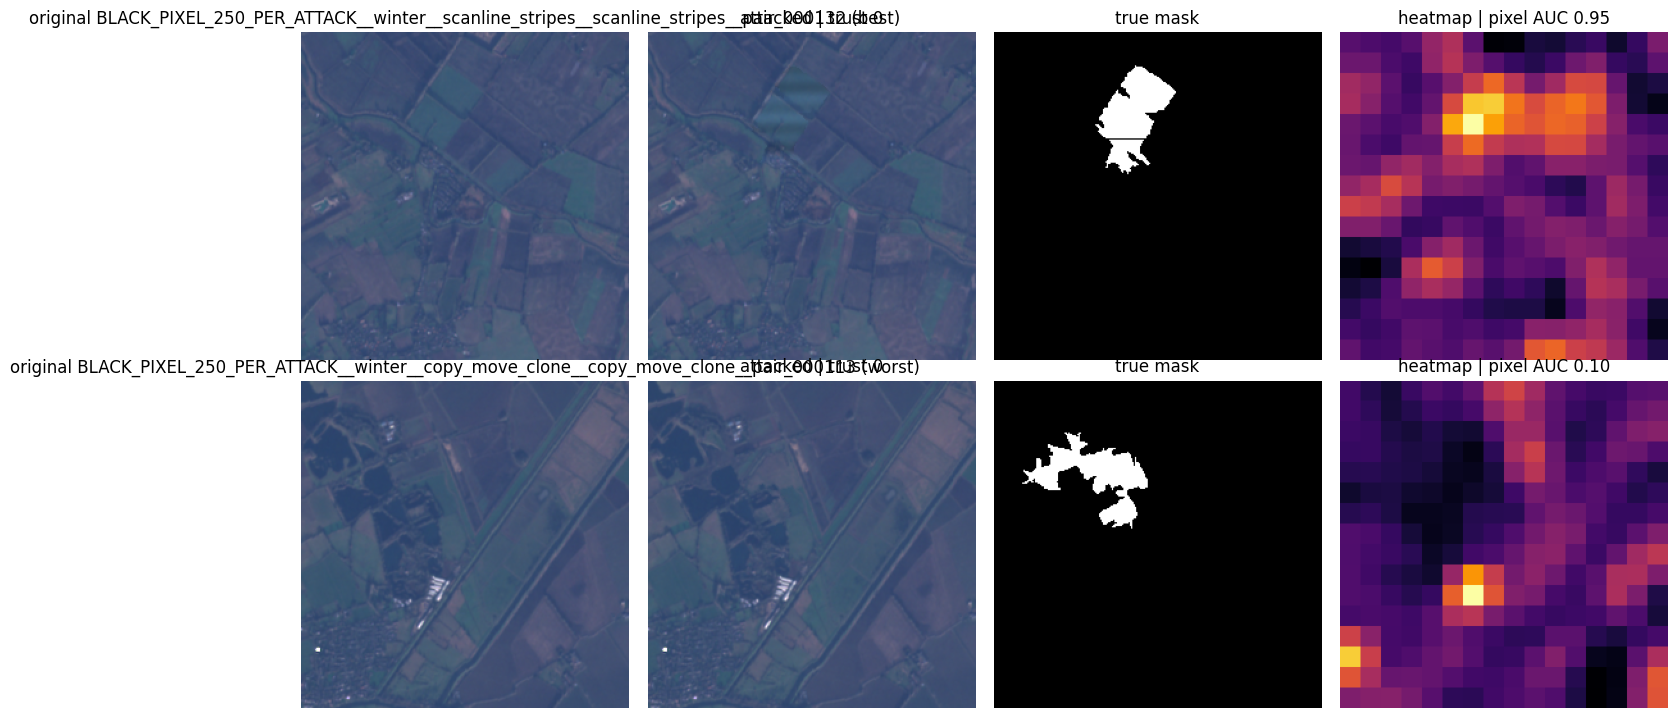

{
 "run_tag": "v3_clean_only",
 "build_id": "73725375",
 "use_local_context": true,
 "hgb_max_iter": 150,
 "test_FPR": 1.0,
 "test_FPR_wilson": [
  0.9929361784754973,
  1.0
 ],
 "test_FPR_scene_boot": [
  1.0,
  1.0
 ],
 "threshold": 1.1963075205170106,
 "pairs_AUC": 0.610120408474318,
 "pairs_AUC_ci": [
  0.5648529187623839,
  0.6619532083523852
 ],
 "pairs_TPR_core": 1.0,
 "pairs_TPR_core_wilson": [
  0.954720325877871,
  0.9999999999999999
 ],
 "mean_IoU": 0.0009331124758180121,
 "mean_pixel_AUC": 0.5110606668570361,
 "n_pairs": 95,
 "n_metadata_only": 14,
 "median_latency_ms": 730.8928754991939,
 "process_memory_MB": 2901.090304
}
saved: ['cost.csv', 'decision_impact.csv', 'detector_arrays.npz', 'export', 'feature_response_z.csv', 'fig_example.png', 'fig_scores.png', 'heatmaps.npz', 'pair_results.csv', 'per_family_results.csv', 'records.json', 'regressors.pkl', 'summary_v3_clean_only.json', 'term_ablation.csv']


In [42]:
check_fresh(test_build_id, pair_build_id)

def to_record(path, res):
    grid7 = zoom(res["heatmap"], 7 / 256, order=1)[:7, :7]
    return dict(tile=os.path.basename(path), trust_score=round(res["trust_score"], 2),
                score=None if np.isinf(res["score"]) else round(res["score"], 3),
                channel_flags={k: bool(v) for k, v in res["channel_flags"].items()},
                heatmap_coarse_7x7=np.round(grid7, 2).tolist())

records = [to_record(p, r_) for p, r_ in zip(paths["test"], test_results)]
for _, p in pairs.iterrows():
    if p["pair_id"] in pair_cache:
        records.append(to_record(p["attacked"], pair_cache[p["pair_id"]]["ra"]))
with open(f"{OUT_DIR}/records.json", "w") as f:
    json.dump(records, f, indent=1)

hm = {os.path.basename(p): r_["heatmap"].astype(np.float16) for p, r_ in zip(paths["test"][:50], test_results[:50])}
hm.update({f"{k}_attacked": v["ra"]["heatmap"].astype(np.float16) for k, v in pair_cache.items()})
np.savez_compressed(f"{OUT_DIR}/heatmaps.npz", **hm)

arrays = {k: model[k] for k in ["mu","sd","loc","precision","p_mu","p_sd","p_loc","p_precision"]}
extra = {k: model[k] for k in ["threshold","heat_thr","tile_thr","patch_thr","fz_thr","hc_thr","fz_k"]}
np.savez(f"{OUT_DIR}/detector_arrays.npz", **extra, **arrays)
with open(f"{OUT_DIR}/regressors.pkl", "wb") as f:
    pickle.dump(dict(regressors=model["regressors"], err_scale=model["err_scale"], p99_ref=model["p99_ref"],
                     feature_names=model["feature_names"], expected_dtype=model["expected_dtype"],
                     local_context=model["local_context"], terms=model["terms"], log_mask=model["log_mask"], band_flag_thresholds=model["band_flag_thresholds"], pixel_log_center=model["pixel_log_center"], pixel_log_scale=model["pixel_log_scale"], predict_stride=model["predict_stride"], dropped_features=model["dropped_features"]), f)

# cost numbers
lat_ms = []
for p in paths["test"][:20]:
    arr = read_tile(p); t = time.perf_counter(); authenticity(arr, model); lat_ms.append((time.perf_counter() - t) * 1000)
size_mb = sum(os.path.getsize(f"{OUT_DIR}/{n}") for n in ["detector_arrays.npz", "regressors.pkl"]) / 1e6
try:
    import psutil; rss_mb = psutil.Process().memory_info().rss / 1e6
except ImportError:
    rss_mb = float("nan")
cost = pd.DataFrame([dict(latency_ms_median=np.median(lat_ms), latency_ms_p95=np.percentile(lat_ms, 95),
                          model_size_MB=size_mb, process_memory_MB=rss_mb)]).round(1)
display(cost)

cost.to_csv(f"{OUT_DIR}/cost.csv", index=False)
pair_results.to_csv(f"{OUT_DIR}/pair_results.csv", index=False)
fam_table.to_csv(f"{OUT_DIR}/per_family_results.csv", index=False)
ablation.to_csv(f"{OUT_DIR}/term_ablation.csv", index=False)
decision.to_csv(f"{OUT_DIR}/decision_impact.csv")
feature_response.to_csv(f"{OUT_DIR}/feature_response_z.csv")

# figure 1: originals vs teammates' attacked scores
"""fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(np.log10(pf[pf.y == 0].score), bins=20, alpha=.7, label="originals")
ax.hist(np.log10(pf[pf.y == 1].score), bins=20, alpha=.5, label="teammates' attacks")
ax.axvline(np.log10(model["threshold"]), color="red", ls="--", label="threshold")
ax.set_xlabel("log10 fused score"); ax.legend(); ax.set_title("Score distributions (real pairs)")
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig_scores.png", dpi=150); plt.show()
"""
# figure 2: best and worst localised local attack (shown honestly, not only the best)
rgb = lambda x: np.clip(np.transpose(x[[B["B4"], B["B3"], B["B2"]]], (1, 2, 0)) / 0.3, 0, 1)
cand = pair_results[(pair_results.size_frac > 0) & (pair_results.size_frac < 0.5)].dropna(subset=["pixel_auc"]).sort_values("pixel_auc")
ids = [cand.iloc[-1].pair, cand.iloc[0].pair] if len(cand) >= 2 else pair_results.pair.tolist()[:1]
fig, axs = plt.subplots(len(ids), 4, figsize=(14, 3.6 * len(ids)), squeeze=False)
for k, pid in enumerate(ids):
    c = pair_cache[pid]; o_r, a_r = pair_arrays[pid]
    pa_ = float(pair_results.loc[pair_results["pair"] == pid, "pixel_auc"].iloc[0])
    axs[k, 0].imshow(rgb(o_r)); axs[k, 0].set_title(f"original {pid}" + (" (best)" if k == 0 and len(ids) > 1 else " (worst)" if k == 1 else ""))
    axs[k, 1].imshow(rgb(a_r)); axs[k, 1].set_title(f"attacked | trust {c['ra']['trust_score']:.0f}")
    axs[k, 2].imshow(c["mask"], cmap="gray"); axs[k, 2].set_title("true mask")
    axs[k, 3].imshow(c["ra"]["heatmap"], cmap="inferno"); axs[k, 3].set_title(f"heatmap | pixel AUC {pa_:.2f}")
    for ax_ in axs[k]: ax_.axis("off")
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/fig_example.png", dpi=150); plt.show()

# headline numbers for the report (all measured in this run)
summary = dict(run_tag=RUN_TAG, build_id=model["build_id"], use_local_context=USE_LOCAL_CONTEXT, hgb_max_iter=HGB_MAX_ITER,
               test_FPR=fpr_test, test_FPR_wilson=list(wilson(k_fp, n_te)), test_FPR_scene_boot=[float(lo_c), float(hi_c)],
               threshold=threshold, pairs_AUC=auc_pairs, pairs_AUC_ci=list(auc_ci),
               pairs_TPR_core=tpr_pairs, pairs_TPR_core_wilson=list(wilson(k_det, n_pix)),
               mean_IoU=float(np.nanmean(iou_vals)), mean_pixel_AUC=float(np.nanmean(pauc_vals)),
               n_pairs=len(pair_results), n_metadata_only=int(pair_results.metadata_only.sum()),
               median_latency_ms=float(np.median(lat_ms)), process_memory_MB=float(rss_mb))
json.dump(summary, open(f"{OUT_DIR}/summary_{RUN_TAG}.json", "w"), indent=1)
print(json.dumps(summary, indent=1))
print("saved:", sorted(os.listdir(OUT_DIR)))

### Before vs after
Run the notebook once with `USE_LOCAL_CONTEXT=False, HGB_MAX_ITER=50, RUN_TAG="v1"` (older regressors) and once with the defaults (`"v2"`); both write `summary_<tag>.json` in the output folder. This cell prints them side by side. Nothing is typed by hand.

In [40]:
runs = {os.path.basename(f)[8:-5]: json.load(open(f)) for f in sorted(glob.glob(f"{OUT_DIR}/summary_*.json"))}
if runs:
    keys = ["use_local_context", "hgb_max_iter", "test_FPR", "test_FPR_wilson", "test_FPR_scene_boot", "pairs_AUC", "pairs_AUC_ci",
            "pairs_TPR_core", "pairs_TPR_core_wilson", "mean_IoU", "mean_pixel_AUC",
            "median_latency_ms", "process_memory_MB"]
    cmp_ = pd.DataFrame({tag: {k: (np.round(v, 3).tolist() if isinstance(v, list) else (round(v, 3) if isinstance(v, float) else v))
                               for k, v in s.items() if k in keys} for tag, s in runs.items()})
    display(cmp_)
else:
    print("no summary files yet")
print("BASELINE (user-reported only): AUC 0.519 | TPR 0 | clean FPR 1.6% (n=126) | latency ~1300 ms")
print("AFTER metrics must come from summary_v3_clean_only.json produced above; never use stale baseline outputs as after numbers.")


,v3_clean_only
use_local_context,True
hgb_max_iter,150
test_FPR,1.0
test_FPR_wilson,"[0.993, 1.0]"
test_FPR_scene_boot,"[1.0, 1.0]"
pairs_AUC,0.61
pairs_AUC_ci,"[0.565, 0.662]"
pairs_TPR_core,1.0
pairs_TPR_core_wilson,"[0.955, 1.0]"
mean_IoU,0.001


BASELINE (user-reported only): AUC 0.519 | TPR 0 | clean FPR 1.6% (n=126) | latency ~1300 ms
AFTER metrics must come from summary_v3_clean_only.json produced above; never use stale baseline outputs as after numbers.


In [45]:
# ============================================================
# FINAL EXPORT: all DataFrames -> CSV, model -> pkl + onnx, everything zipped
# ============================================================
import shutil
FINAL_DIR = f"{OUT_DIR}/final_export"
os.makedirs(f"{FINAL_DIR}/csv", exist_ok=True)
os.makedirs(f"{FINAL_DIR}/model", exist_ok=True)

# warn (not stop) if the model was rebuilt after the results were computed
try:
    check_fresh(test_build_id, pair_build_id)
except Exception as e:
    print("WARNING: results may be stale ->", e)

# ---- 1. every DataFrame in the notebook -> CSV (named after its variable)
seen, saved = set(), []
for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame) and not name.startswith("_") and id(obj) not in seen and len(obj) > 0:
        seen.add(id(obj))
        keep_index = not isinstance(obj.index, pd.RangeIndex)      # keep meaningful indexes (e.g. feature_response)
        obj.to_csv(f"{FINAL_DIR}/csv/{name}.csv", index=keep_index)
        saved.append((name, obj.shape))
print("CSV saved:", saved)

# ---- 2. pickle: whole detector + constants
config = dict(BAND_NAMES=BAND_NAMES, TARGET_BANDS=TARGET_BANDS, PATCH=PATCH, PATCH_STRIDE=PATCH_STRIDE,
              PREDICT_STRIDE=PREDICT_STRIDE, Z_CLIP=Z_CLIP, FZ_K=FZ_K, USE_LOCAL_CONTEXT=USE_LOCAL_CONTEXT,
              ALL_TERMS=ALL_TERMS, FUSED_TERMS=FUSED_TERMS, FPR_TARGET=FPR_TARGET,
              BAND_FLAG_FRAC=BAND_FLAG_FRAC, HARD_FLAGS=HARD_FLAGS)
pkl_path = f"{FINAL_DIR}/model/detector_full.pkl"
with open(pkl_path, "wb") as f:
    pickle.dump(dict(model=model, config=config, run_tag=RUN_TAG), f, protocol=4)
print(f"pickle: {os.path.getsize(pkl_path)/1e6:.1f} MB")

# ---- 3. ONNX for the 7 cross-band regressors (with the bool-attribute fix)
_ensure("skl2onnx"); _ensure("onnxruntime"); _ensure("onnx")
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType
import onnxruntime as ort
import skl2onnx.common._container as _cont
if not hasattr(_cont, "_orig_make_node"):
    _cont._orig_make_node = _cont.make_node
    def _make_node_fixed(op_type, inputs, outputs, name=None, **kw):
        for k, v in list(kw.items()):
            if isinstance(v, (list, tuple, np.ndarray)) and len(v) and any(isinstance(x, (bool, np.bool_)) for x in v):
                kw[k] = [int(x) for x in v]
        return _cont._orig_make_node(op_type, inputs, outputs, name=name, **kw)
    _cont.make_node = _make_node_fixed

n_in = len(input_cols(0))
X_chk = pixel_inputs(to_reflectance(read_tile(paths["test"][0])))[::13]
worst = 0.0
for b in TARGET_BANDS:
    try:
        onx = convert_sklearn(model["regressors"][b], initial_types=[("X", FloatTensorType([None, n_in]))])
        p = f"{FINAL_DIR}/model/regressor_{b}.onnx"
        with open(p, "wb") as f:
            f.write(onx.SerializeToString())
        Xb = X_chk[:, input_cols(B[b])].astype(np.float32)
        d = float(np.abs(ort.InferenceSession(p, providers=["CPUExecutionProvider"]).run(None, {"X": Xb})[0].ravel()
                         - model["regressors"][b].predict(Xb)).max())
        worst = max(worst, d); print(f"  onnx {b}: max diff vs sklearn {d:.2e}")
    except Exception as e:
        print(f"  onnx {b} FAILED: {str(e)[:200]}")
print("ONNX check:", "OK" if worst < 1e-3 else "DIFFERS or incomplete, do not rely on these files")

# ---- 4. also include figures / earlier outputs, then zip everything for download
for fn in os.listdir(OUT_DIR):
    src = f"{OUT_DIR}/{fn}"
    if os.path.isfile(src):
        shutil.copy(src, f"{FINAL_DIR}/{fn}")
zip_base = f"{OUT_DIR}/track3_results"
shutil.make_archive(zip_base, "zip", FINAL_DIR)
print(f"\nZIP ready: {zip_base}.zip ({os.path.getsize(zip_base + '.zip')/1e6:.1f} MB)")
print("contents:", sorted(os.listdir(FINAL_DIR)), "| csv:", len(os.listdir(f"{FINAL_DIR}/csv")), "files")
try:
    from IPython.display import FileLink
    display(FileLink(f"{zip_base}.zip".replace("/kaggle/working/", "")))
except Exception:
    pass

CSV saved: [('pairs', (710, 6)), ('whole', (2400, 5)), ('source_mapping', (710, 4)), ('unmapped', (710, 4)), ('df', (2400, 6)), ('flag_table', (100, 6)), ('tf', (540, 6)), ('pair_results', (95, 23)), ('pix', (81, 20)), ('g', (17, 6)), ('fam_table', (1, 6)), ('Z', (81, 125)), ('feature_response', (1, 124)), ('ablation', (7, 6)), ('pf', (162, 5)), ('decision', (1, 6)), ('cost', (1, 4)), ('cand', (64, 23)), ('cmp_', (13, 1)), ('demo', (15, 7))]
pickle: 2.3 MB
  onnx B2: max diff vs sklearn 1.61e-04
  onnx B3: max diff vs sklearn 1.87e-08
  onnx B4: max diff vs sklearn 3.04e-08
  onnx B5: max diff vs sklearn 3.15e-08
  onnx B8: max diff vs sklearn 4.82e-08
  onnx B11: max diff vs sklearn 1.20e-03
  onnx B12: max diff vs sklearn 4.85e-08
ONNX check: DIFFERS or incomplete, do not rely on these files

ZIP ready: /kaggle/working/outputs/track3_results.zip (3.3 MB)
contents: ['cost.csv', 'csv', 'decision_impact.csv', 'detector_arrays.npz', 'feature_response_z.csv', 'fig_example.png', 'fig_score

/kaggle/working/outputs/track3_results.zip